# Exploratory Data Analysis of Spotify Tracks

**Consolidated project notebook — integration draft**  
Team size: 4 · Submission deadline: 25 November 2026

This is the single notebook intended to contain the whole project's analysis. It follows the flat, notebook-centered layout of the supplied reference repository. The official CSV and data dictionary sit beside this notebook. The raw data is never overwritten.

> **Integration status (24 November 2026):** dataset inspection, cleaning logic, leader actual temporal analysis, year-over-year growth, and preliminary recommendation evidence are included. Member 1's univariate charts, Member 2's bivariate section, Member 3's multivariate/outlier section, the subjective-answer PDF, and final integration review remain pending.


## 1. Project objective and questions

Describe the supplied Spotify tracks dataset; profile its variables; examine relationships among audio features and popularity; compare selected groups; and study changes over release year. Recommendations must follow evidence. This observational dataset can show associations, not prove that a musical feature causes popularity.

The official problem statement has four analysis areas: **Univariate, Bivariate, Multivariate, and Time-series/Temporal**. It also requires a well-commented notebook, a PDF answering the subjective questions, and a README. The PDF remains a separate required deliverable; this notebook is the consolidated code and analysis file.


## 2. Team responsibilities and integration status

| Owner | Section | Status in this notebook |
|---|---|---|
| Leader | Data foundation, temporal analysis, recommendations, final integration | Actuals and year-over-year growth questions are covered; recommendations need final review after teammate analyses. |
| Member 1 | Data cleaning review and Univariate Analysis | **Pending:** add verified distributions, plots, interpretations, and sample sizes here. |
| Member 2 | Bivariate Analysis | **Pending:** add relationship plots and a coefficient table with valid sample sizes here. |
| Member 3 | Multivariate and Outlier Analysis | **Pending:** add defined group comparisons, multivariate graphs, outlier method, and inspected results here. |

Members may use temporary notebooks to work, but the final submitted project analysis must be integrated into this one notebook.


## 3. Libraries

Pandas reads and summarizes the table. NumPy is available for simple numeric work. Matplotlib and Seaborn make the graphs.

The shared module `src/spotify_chart_style.py` applies the Spotify Premium dark editorial theme (colours, fonts, gridlines, export quality) to every chart. Teammates can import the same module for their sections so all graphs look consistent.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.spotify_chart_style import (
    apply_spotify_style, spotify_green, muted_grey, muted_blue, muted_sand,
)

apply_spotify_style()


## 4. Load the supplied dataset

Run Jupyter from the project root so the notebook can read the CSV beside it. The file `spotify_tracks.csv` is copied from the dataset folder provided with the problem statement.


In [2]:
df = pd.read_csv('spotify_tracks.csv')
print(df.head())


                 track_id  ... language
0  2r0ROhr7pRN4MXDMT1fEmd  ...    Tamil
1  4I38e6Dg52a2o2a8i5Q5PW  ...    Tamil
2  59NoiRhnom3lTeRFaBzOev  ...    Tamil
3  5uUqRQd385pvLxC8JX3tXn  ...    Tamil
4  1KaBRg2xgNeCljmyxBH1mo  ...    Tamil

[5 rows x 22 columns]


## 5. Inspect the data structure

Check row and column counts, column names, data types, blank values, duplicates, ID repeats, year range, and language categories before analysis.


In [3]:
print('Rows and columns:', df.shape)
print('Column names:', list(df.columns))
print('Data types:')
print(df.dtypes)
print('Blank cells:', df.isna().sum().sum())
print('Exact duplicate rows:', df.duplicated().sum())
print('Duplicate track IDs:', df['track_id'].duplicated().sum())
print('Year range:', df['year'].min(), 'to', df['year'].max())
print('Language counts:')
print(df['language'].value_counts(dropna=False))


Rows and columns: (62317, 22)
Column names: ['track_id', 'track_name', 'artist_name', 'year', 'popularity', 'artwork_url', 'album_name', 'acousticness', 'danceability', 'duration_ms', 'energy', 'instrumentalness', 'key', 'liveness', 'loudness', 'mode', 'speechiness', 'tempo', 'time_signature', 'valence', 'track_url', 'language']
Data types:
track_id                str
track_name              str
artist_name             str
year                  int64
popularity            int64
artwork_url             str
album_name              str
acousticness        float64
danceability        float64
duration_ms         float64
energy              float64
instrumentalness    float64
key                 float64
liveness            float64
loudness            float64
mode                float64
speechiness         float64
tempo               float64
time_signature      float64
valence             float64
track_url               str
language                str
dtype: object
Blank cells: 0
Exact duplic

### Numeric summary of the raw file

These values include the invalid extraction sentinels and duplicate rows. Use them to understand the source; use the processed copy for analysis.


In [4]:
print(df.describe().T)


                    count           mean  ...          75%          max
year              62317.0    2014.425935  ...    2022.0000     2024.000
popularity        62317.0      15.358361  ...      26.0000       93.000
acousticness      62317.0       0.362292  ...       0.6320        0.996
danceability      62317.0       0.596807  ...       0.7300        0.986
duration_ms       62317.0  242527.040021  ...  286240.0000  4581483.000
energy            62317.0       0.602496  ...       0.8030        1.000
instrumentalness  62317.0       0.146215  ...       0.0152        0.999
key               62317.0       5.101658  ...       8.0000       11.000
liveness          62317.0       0.194143  ...       0.2430        0.998
loudness          62317.0     -65.103433  ...      -5.4560        1.233
mode              62317.0       0.586052  ...       1.0000        1.000
speechiness       62317.0       0.087722  ...       0.0891        0.959
tempo             62317.0     117.931247  ...     135.0810      

## 6. Data cleaning

The source contains 78 exact repeated rows. It also contains 35 records with -1 in 11 audio/code fields and -100,000 loudness in the same records. That shared pattern indicates failed feature extraction. We remove only exact duplicate rows and mark the 12 sentinel measurements missing. We do not impute values or delete those records. The raw CSV remains unchanged.

The supplied data dictionary and local source audit are available as `spotify_data_description.csv` and in `outputs/reports/REFERENCE_AUDIT.md`.


In [5]:
df_clean = df.drop_duplicates().copy()
sentinel_columns = [
    'acousticness', 'danceability', 'energy', 'instrumentalness',
    'key', 'liveness', 'mode', 'speechiness', 'tempo',
    'time_signature', 'valence'
]

for column in sentinel_columns:
    df_clean.loc[df_clean[column] == -1, column] = np.nan

df_clean.loc[df_clean['loudness'] <= -1000, 'loudness'] = np.nan

print('Processed shape:', df_clean.shape)
print('Missing cells after marking sentinels:', df_clean.isna().sum().sum())
print('Duplicate rows after cleaning:', df_clean.duplicated().sum())
print('Duplicate track IDs after cleaning:', df_clean['track_id'].duplicated().sum())

df_clean.to_csv('data/processed/cleaned_spotify_tracks.csv', index=False)


Processed shape: (62239, 22)
Missing cells after marking sentinels: 420
Duplicate rows after cleaning: 0
Duplicate track IDs after cleaning: 0


### Processed data profile

The code below summarizes the cleaned working table. Missing feature values are skipped by Pandas summary functions. URL and free-text fields are not inputs to numeric routines.


In [6]:
numeric_columns = df_clean.select_dtypes(include='number').columns
print(df_clean[numeric_columns].describe().T)


                    count           mean  ...            75%          max
year              62239.0    2014.417969  ...    2022.000000     2024.000
popularity        62239.0      15.357589  ...      26.000000       93.000
acousticness      62204.0       0.363108  ...       0.633000        0.996
danceability      62204.0       0.597667  ...       0.730000        0.986
duration_ms       62239.0  242603.445557  ...  286303.500000  4581483.000
energy            62204.0       0.603318  ...       0.803000        1.000
instrumentalness  62204.0       0.146699  ...       0.015200        0.999
key               62204.0       5.104977  ...       8.000000       11.000
liveness          62204.0       0.194844  ...       0.243000        0.998
loudness          62204.0      -8.945049  ...      -5.454000        1.233
mode              62204.0       0.586956  ...       1.000000        1.000
speechiness       62204.0       0.088353  ...       0.089125        0.959
tempo             62204.0     117.9906

In [7]:
language_summary = df_clean.groupby('language').agg(
    track_count=('track_id', 'count'),
    average_popularity=('popularity', 'mean'),
    median_popularity=('popularity', 'median'),
    average_energy=('energy', 'mean')
).sort_values('track_count', ascending=False)
print(language_summary.round(2))


           track_count  average_popularity  median_popularity  average_energy
language                                                                     
English          23389               14.76                5.0            0.53
Unknown          13005               12.26                4.0            0.61
Tamil            12609               11.91                3.0            0.62
Korean            6893               27.55               26.0            0.76
Hindi             5740               18.20               11.0            0.65
Telugu             321               14.32                9.0            0.67
Malayalam          282                7.32                2.0            0.68


## 7. Univariate Analysis — Member 1

**Status: pending teammate handoff.** Add the finished, beginner-readable analysis in this section. Cover distributions and summary statistics for popularity, duration, key, tempo, acousticness, loudness, danceability, energy, time signature, speechiness, valence, instrumentalness, liveness, mode, and language.

Required discussion includes mean/median and quartiles where useful, frequency counts for categorical fields, plots with clear labels, and a note that a continuous variable such as energy needs defined bins before a mode is meaningful. Do not repeat the invalid -1 sentinels as real values.

**Insert Member 1's reviewed code cells, graphs, interpretations, and findings below.**


## 8. Bivariate Analysis — Member 2

**Status: pending teammate handoff.** Test the official question pairs: duration/popularity; danceability/popularity; energy/popularity; loudness/popularity; acousticness/popularity; valence/popularity; instrumentalness/popularity; liveness/popularity; tempo/popularity; language/popularity; key and mode/popularity; time_signature/popularity.

Use scatter plots for continuous pairs and grouped plots for categorical comparisons. Include the method, coefficient, direction, strength, and valid pair count. Pearson describes linear association; it does not prove causation.

Initial leader evidence for recommendation context (to cross-check, not a substitute for Member 2's section): energy/popularity r=0.147, danceability/popularity r=0.042, valence/popularity r=0.009, acousticness/popularity r=-0.138, and instrumentalness/popularity r=-0.127. These are weak correlations.

**Insert Member 2's reviewed code cells, graphs, interpretations, and findings below.**


## 9. Multivariate and Outlier Analysis — Member 3

**Status: pending teammate handoff.** Examine feature combinations, including danceability/energy/valence among the highest popularity quartile; acousticness/instrumentalness/speechiness; loudness/tempo/mode; language-specific audio features; joint key/mode/time_signature groups; and duration/liveness among high-popularity tracks by decade.

Define popularity groups and any clustering method. For outliers, state the rule, bounds, counts, and percentages, then inspect examples. An IQR flag is not automatically an error. Do not write “hit recipe” or causal conclusions from observational group averages.

**Insert Member 3's reviewed code cells, graphs, interpretations, and findings below.**


## 10. Temporal Analysis — Leader

This completed section groups the processed data by release year. Years with fewer than 30 tracks stay in the summary and count graph. In trend plots they appear as faint points and are not connected in the emphasized line. The 30-track cutoff is a visual aid, not a statistical test.


In [8]:
yearly_track_count = df_clean.groupby('year')['track_id'].count().sort_index()
print(yearly_track_count)


year
1971      12
1972      21
1973      62
1974      10
1975      19
1976       9
1977      39
1978      14
1979      46
1980      20
1981      37
1982     164
1983     176
1984     213
1985     256
1986     260
1987     210
1988     230
1989     297
1990     416
1991     268
1992     405
1993     366
1994     522
1995     457
1996     306
1997     412
1998     292
1999     296
2000     376
2001     493
2002     494
2003     594
2004     527
2005     854
2006     786
2007     865
2008     977
2009    1182
2010    1588
2011    1621
2012    1965
2013    3362
2014    2787
2015    2626
2016    2821
2017    2896
2018    2971
2019    2807
2020    3035
2021    3698
2022    5181
2023    6427
2024    5471
Name: track_id, dtype: int64


In [9]:
yearly_summary = df_clean.groupby('year').agg(
    track_count=('track_id', 'count'),
    average_popularity=('popularity', 'mean'),
    median_popularity=('popularity', 'median'),
    average_energy=('energy', 'mean'),
    average_danceability=('danceability', 'mean'),
    average_valence=('valence', 'mean')
).sort_index()
print(yearly_summary.head())


      track_count  ...  average_valence
year               ...                 
1971           12  ...         0.397050
1972           21  ...         0.722048
1973           62  ...         0.533889
1974           10  ...         0.502420
1975           19  ...         0.597632

[5 rows x 6 columns]


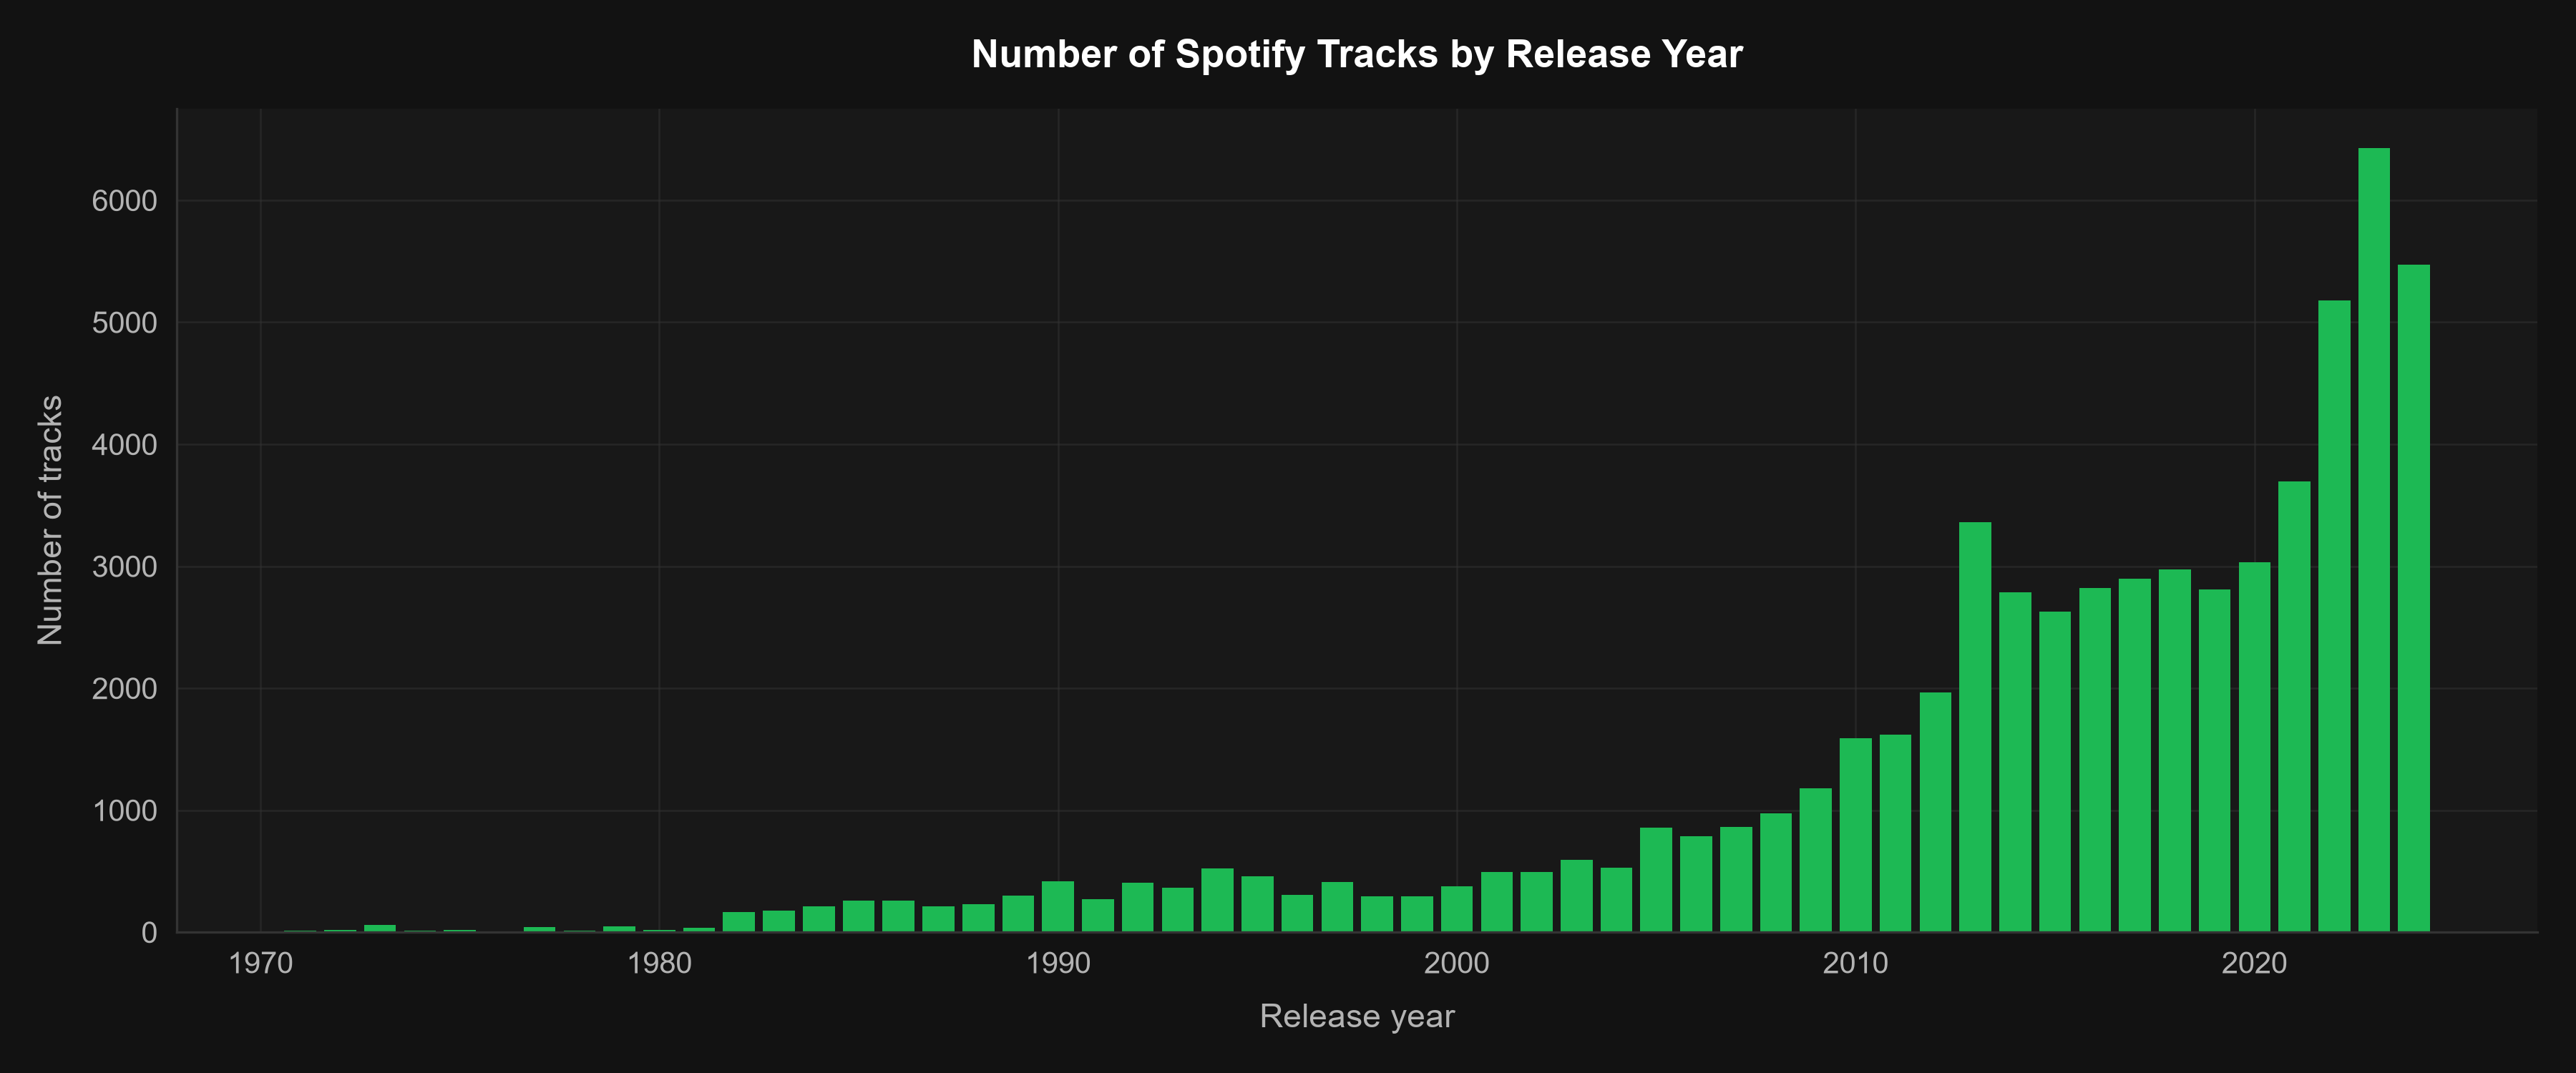

In [10]:
minimum_tracks = 30
reliable_years = yearly_track_count[yearly_track_count >= minimum_tracks].index

plt.figure(figsize=(12, 5))
plt.bar(yearly_track_count.index, yearly_track_count.values, color=spotify_green, edgecolor='none')
plt.title('Number of Spotify Tracks by Release Year')
plt.xlabel('Release year')
plt.ylabel('Number of tracks')
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_track_count.png', dpi=300)
plt.show(block=False)
plt.close()


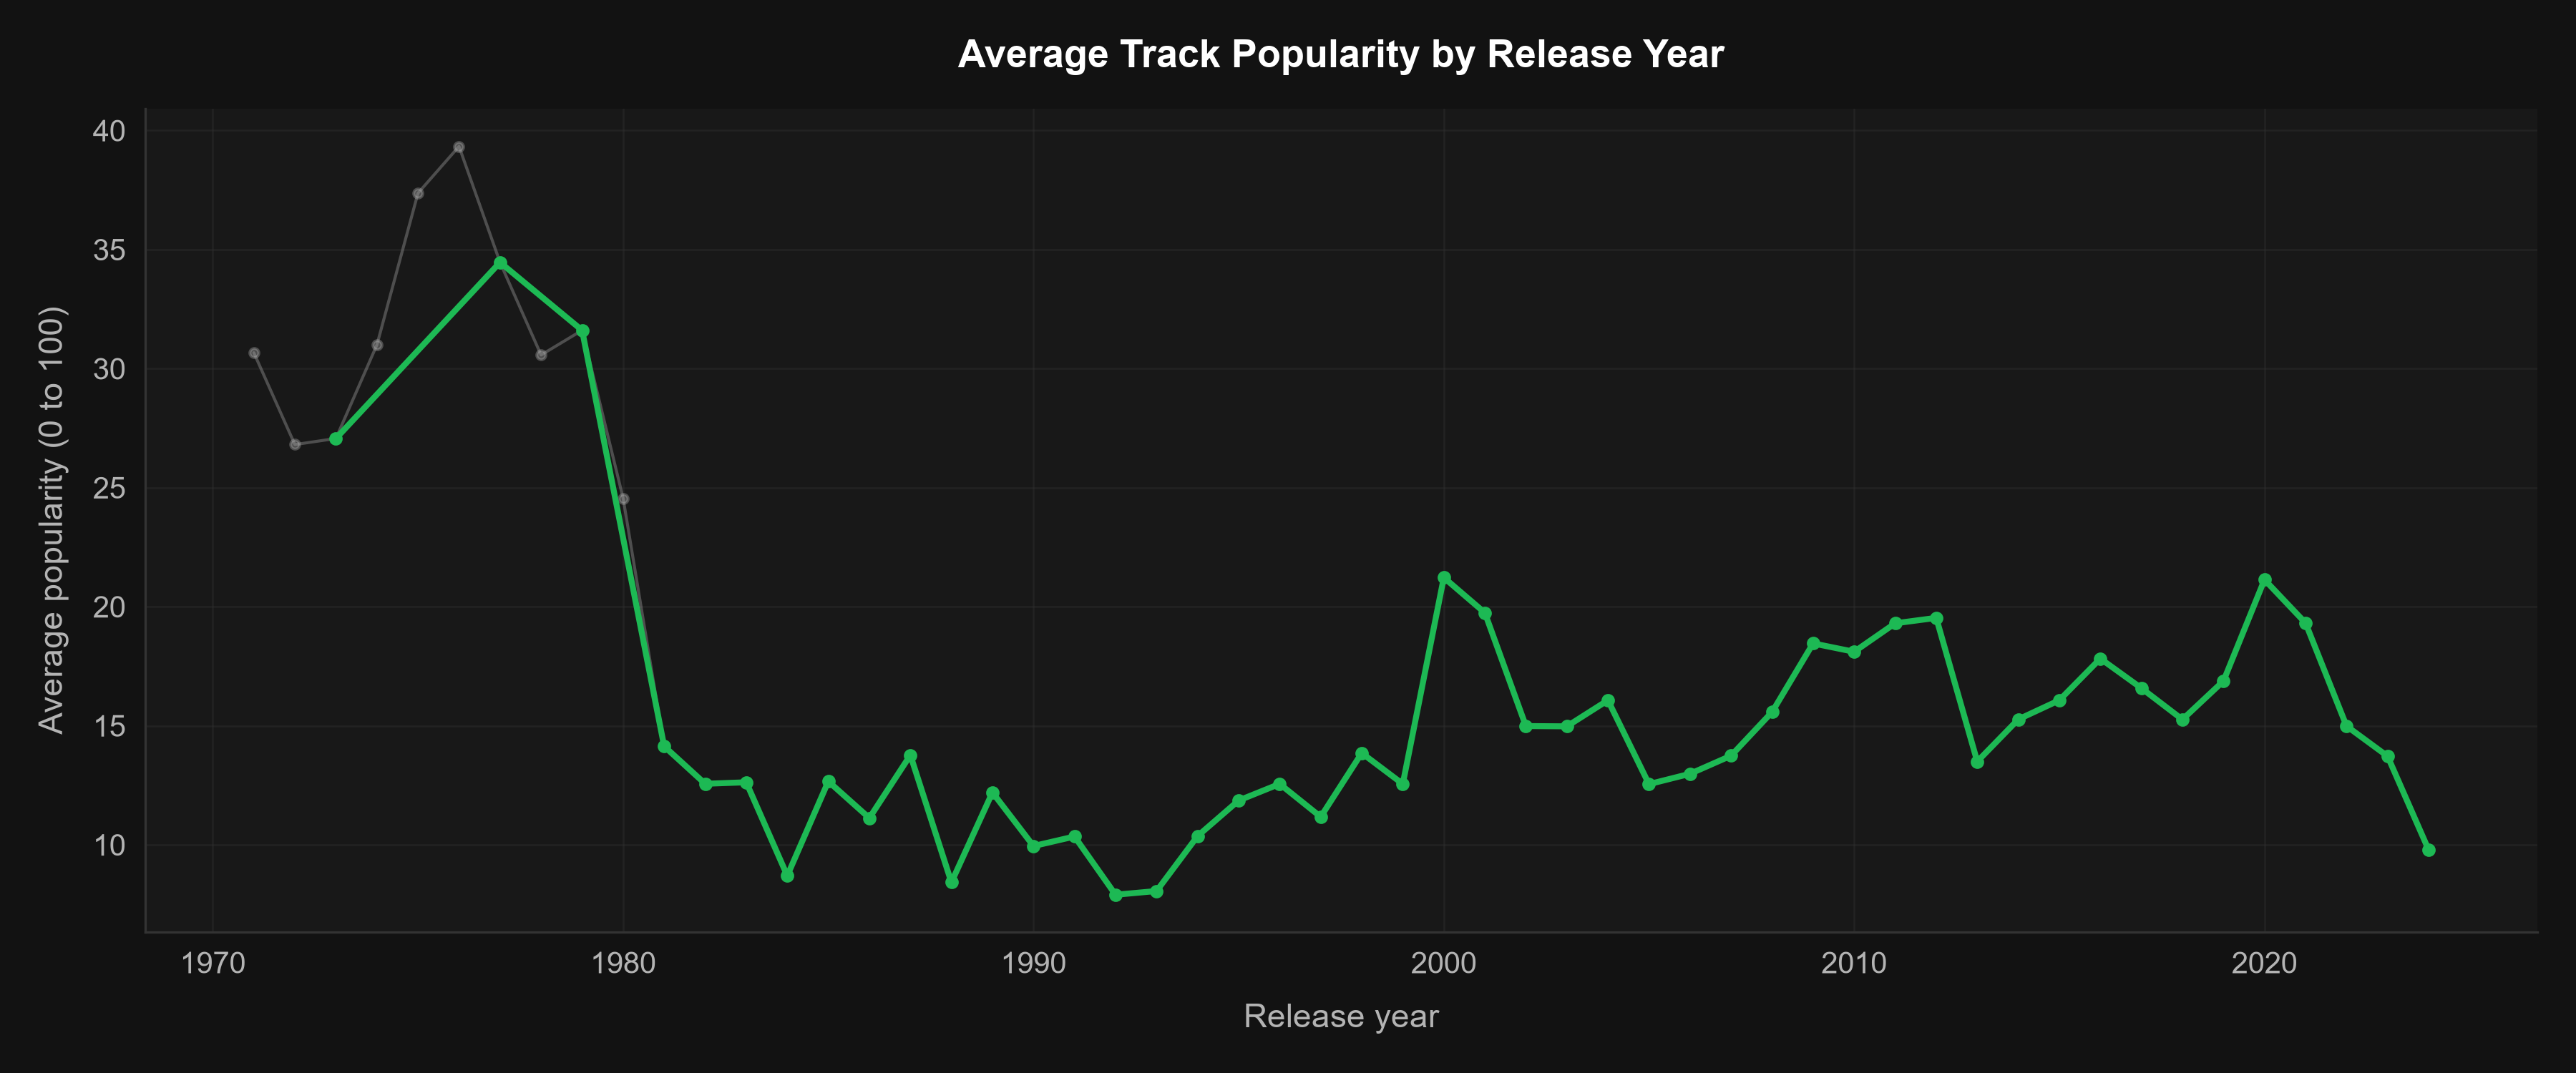

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary.index, yearly_summary['average_popularity'], color=muted_grey, marker='o', markersize=3, linewidth=1, alpha=0.35)
plt.plot(reliable_years, yearly_summary.loc[reliable_years, 'average_popularity'], color=spotify_green, marker='o', markersize=3.5, linewidth=2)
plt.title('Average Track Popularity by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average popularity (0 to 100)')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_average_popularity.png', dpi=300)
plt.show(block=False)
plt.close()


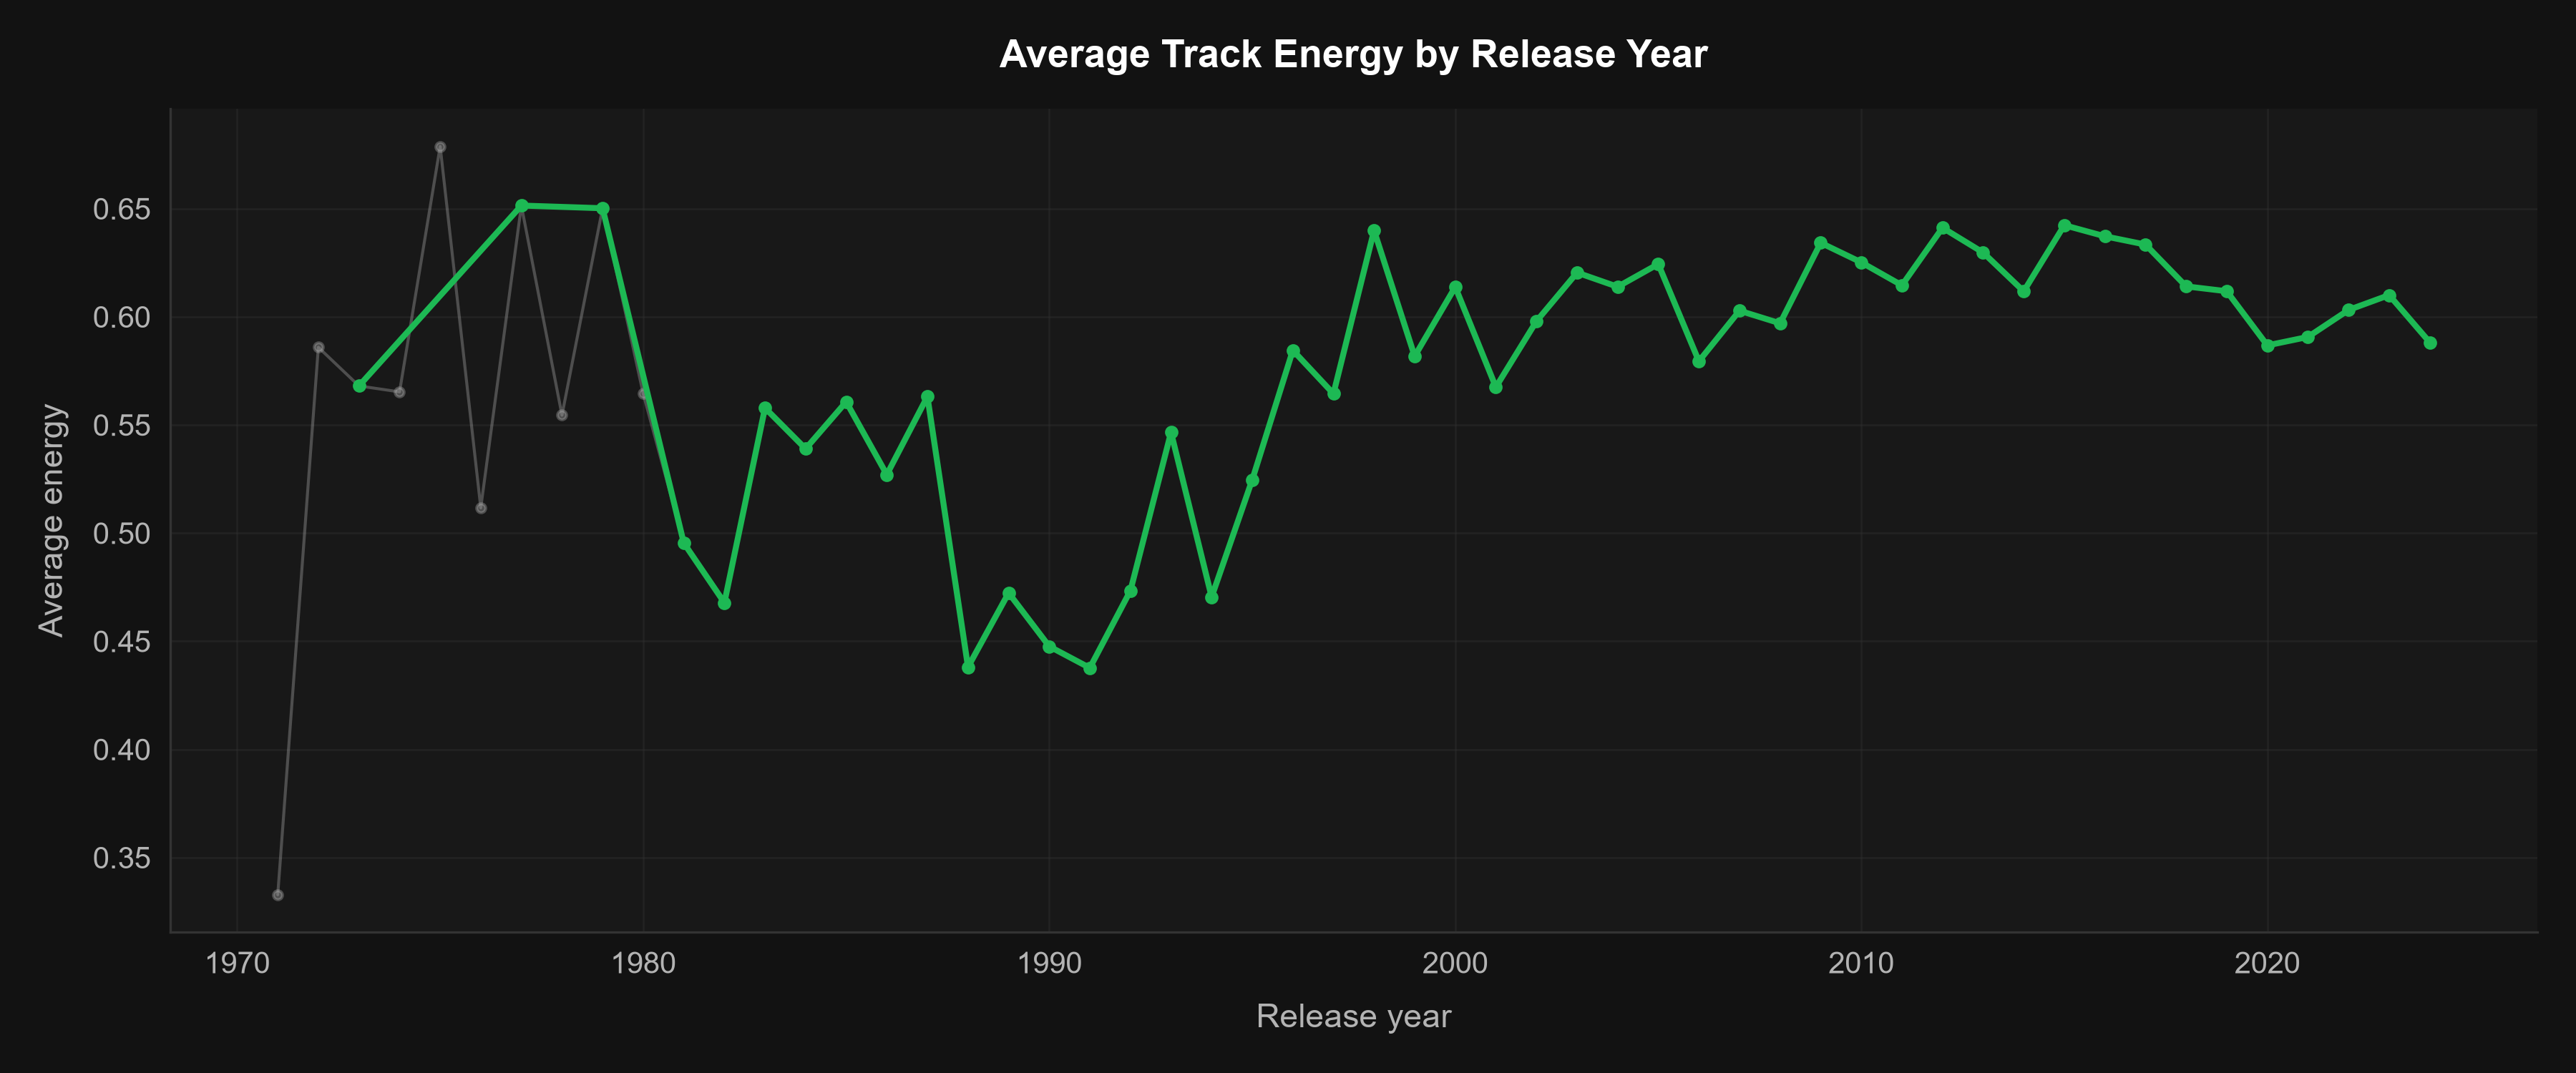

In [12]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary.index, yearly_summary['average_energy'], color=muted_grey, marker='o', markersize=3, linewidth=1, alpha=0.35)
plt.plot(reliable_years, yearly_summary.loc[reliable_years, 'average_energy'], color=spotify_green, marker='o', markersize=3.5, linewidth=2)
plt.title('Average Track Energy by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average energy')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_average_energy.png', dpi=300)
plt.show(block=False)
plt.close()


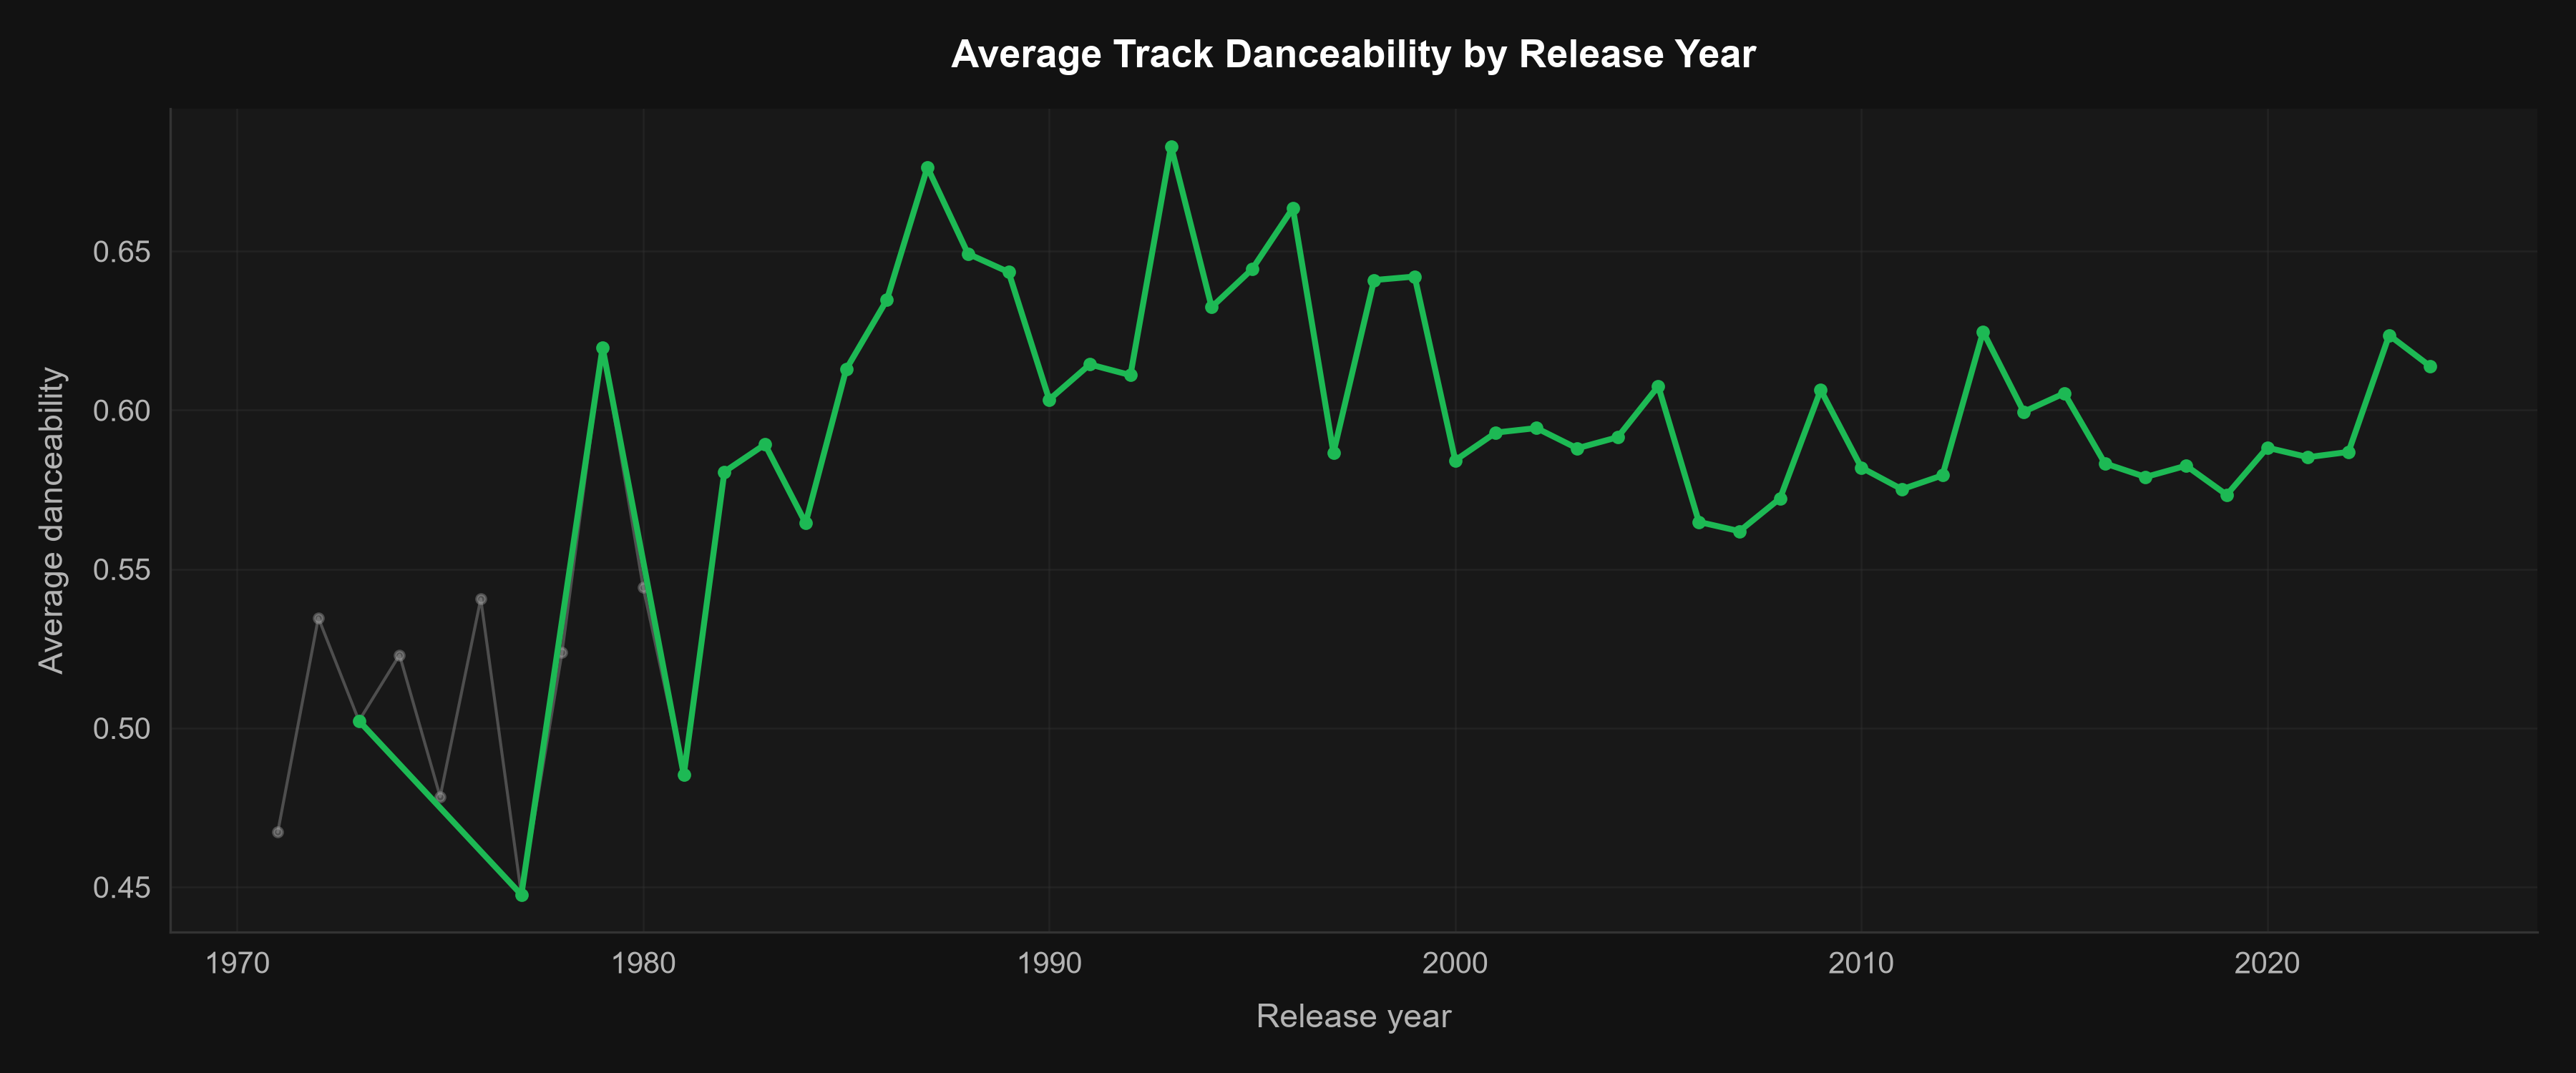

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary.index, yearly_summary['average_danceability'], color=muted_grey, marker='o', markersize=3, linewidth=1, alpha=0.35)
plt.plot(reliable_years, yearly_summary.loc[reliable_years, 'average_danceability'], color=spotify_green, marker='o', markersize=3.5, linewidth=2)
plt.title('Average Track Danceability by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average danceability')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_average_danceability.png', dpi=300)
plt.show(block=False)
plt.close()


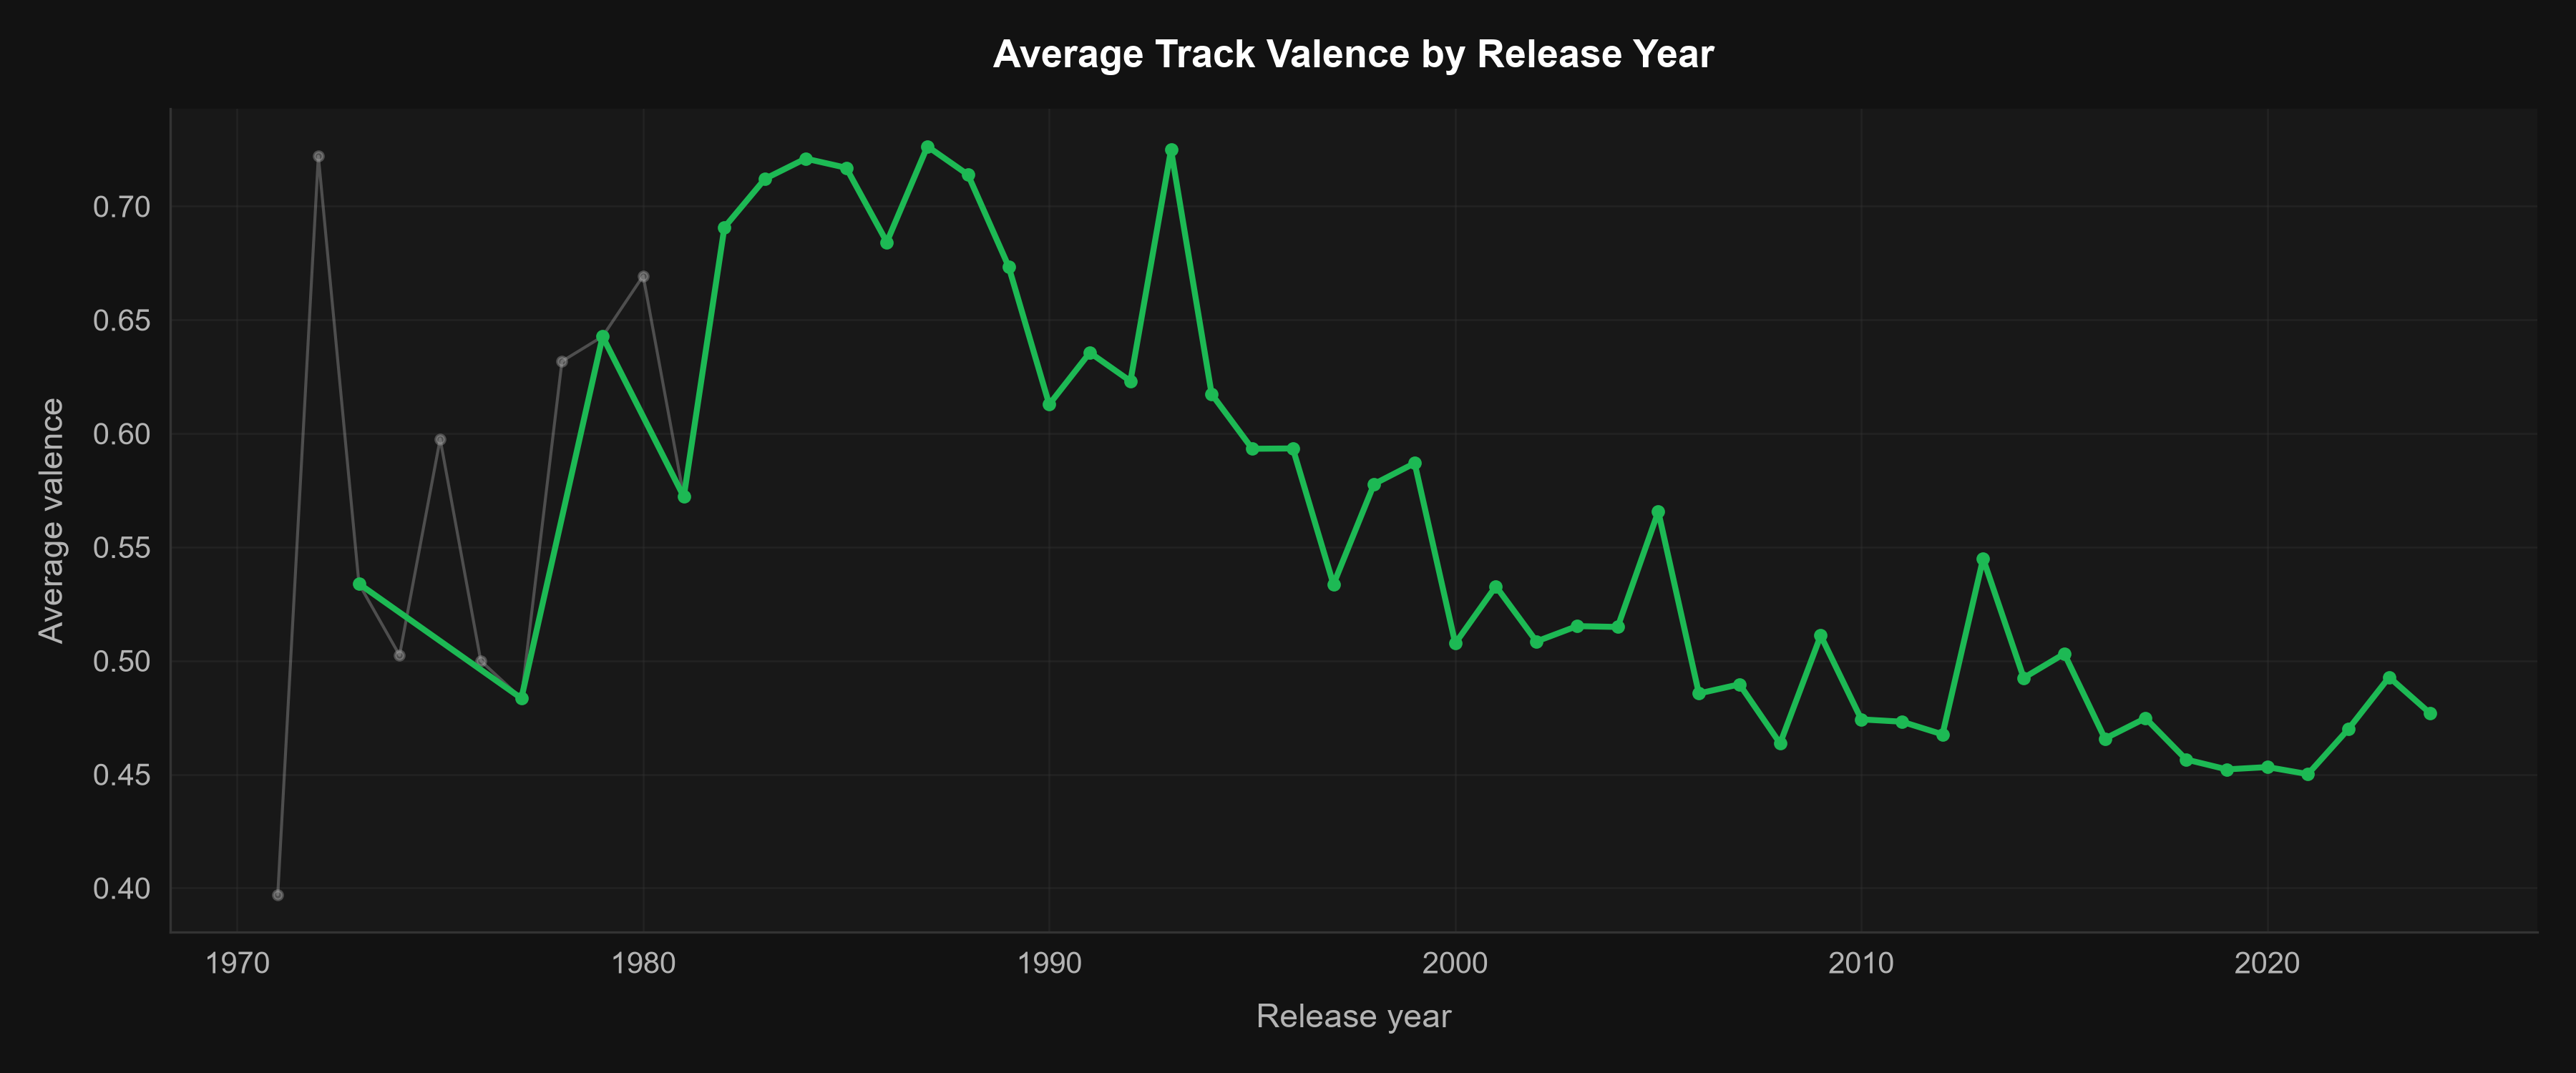

In [14]:
plt.figure(figsize=(12, 5))
plt.plot(yearly_summary.index, yearly_summary['average_valence'], color=muted_grey, marker='o', markersize=3, linewidth=1, alpha=0.35)
plt.plot(reliable_years, yearly_summary.loc[reliable_years, 'average_valence'], color=spotify_green, marker='o', markersize=3.5, linewidth=2)
plt.title('Average Track Valence by Release Year')
plt.xlabel('Release year')
plt.ylabel('Average valence')
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/yearly_average_valence.png', dpi=300)
plt.show(block=False)
plt.close()


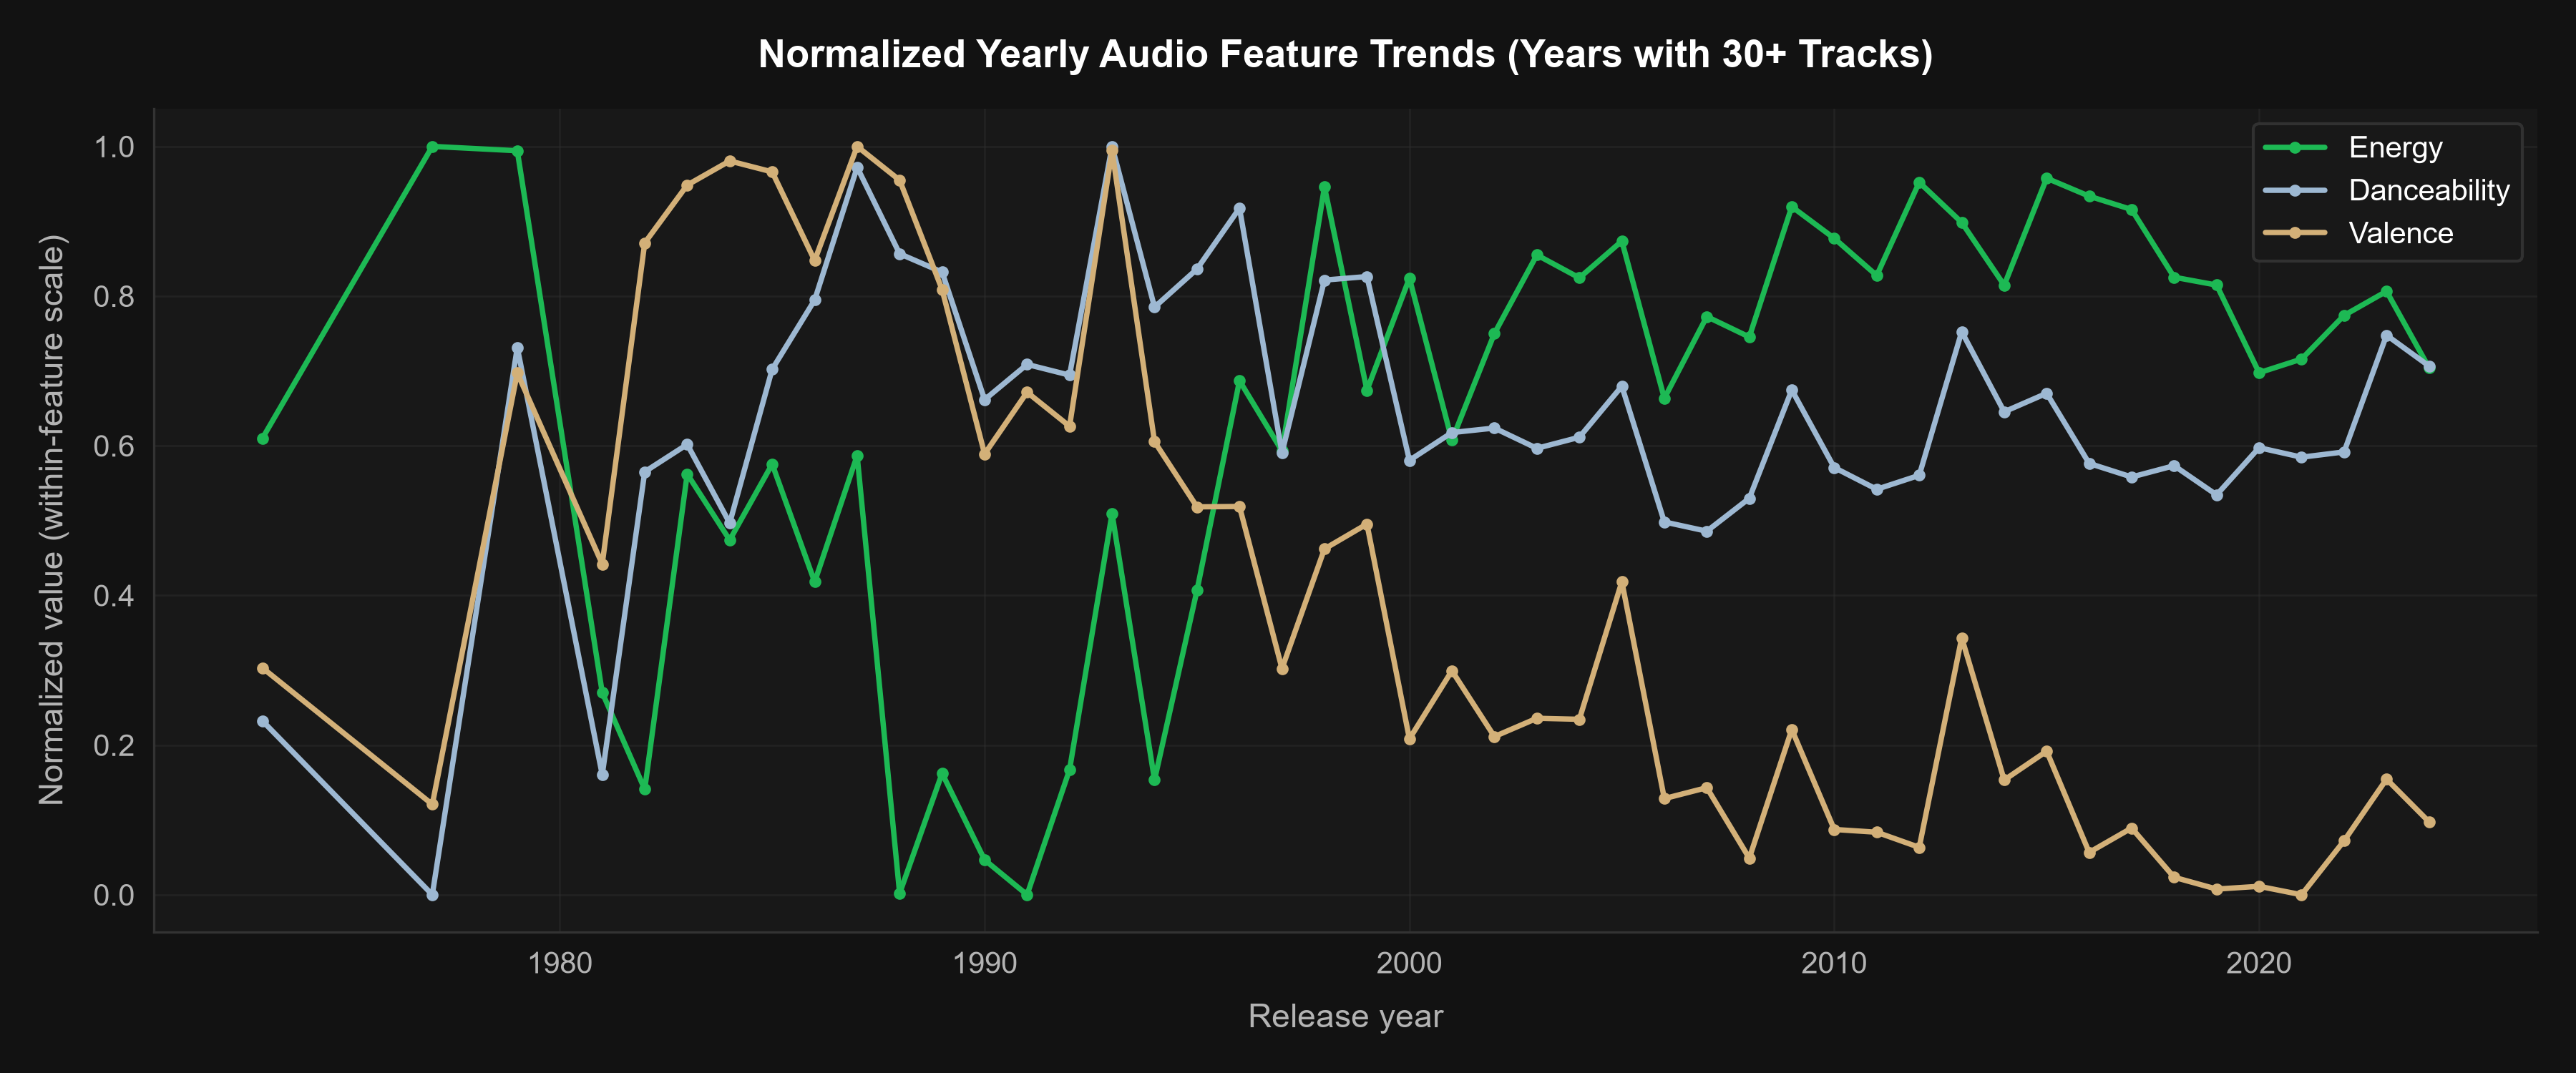

In [15]:
yearly_energy = df_clean.groupby('year')['energy'].mean().sort_index()
yearly_danceability = df_clean.groupby('year')['danceability'].mean().sort_index()
yearly_valence = df_clean.groupby('year')['valence'].mean().sort_index()

combined_features = pd.DataFrame({
    'Energy': yearly_energy,
    'Danceability': yearly_danceability,
    'Valence': yearly_valence
}).loc[reliable_years]

normalized_features = (combined_features - combined_features.min()) / (combined_features.max() - combined_features.min())

feature_colors = {'Energy': spotify_green, 'Danceability': muted_blue, 'Valence': muted_sand}

plt.figure(figsize=(12, 5))
for column in normalized_features.columns:
    plt.plot(normalized_features.index, normalized_features[column], color=feature_colors[column], marker='o', markersize=3, linewidth=1.8, label=column)
plt.title('Normalized Yearly Audio Feature Trends (Years with 30+ Tracks)')
plt.xlabel('Release year')
plt.ylabel('Normalized value (within-feature scale)')
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.savefig('outputs/graphs/temporal/combined_temporal_features.png', dpi=300)
plt.show(block=False)
plt.close()


In [16]:
print('Most represented year:', int(yearly_track_count.idxmax()), '-', int(yearly_track_count.max()), 'tracks')
print('Least represented year:', int(yearly_track_count.idxmin()), '-', int(yearly_track_count.min()), 'tracks')
print('Years with fewer than', minimum_tracks, 'tracks:', list(yearly_track_count[yearly_track_count < minimum_tracks].index))
print('Year with highest mean popularity:', int(yearly_summary['average_popularity'].idxmax()))
print('Year with lowest mean popularity:', int(yearly_summary['average_popularity'].idxmin()))


Most represented year: 2023 - 6427 tracks
Least represented year: 1976 - 9 tracks
Years with fewer than 30 tracks: [1971, 1972, 1974, 1975, 1976, 1978, 1980]
Year with highest mean popularity: 1976
Year with lowest mean popularity: 1992


### Temporal interpretation

The file spans 1971–2024. Track count is highest in 2023 (6,427) and lowest in 1976 (9). Mean popularity is highest in 1976 (39.33, n=9) and lowest in 1992 (7.90, n=405). Among years with at least 30 tracks, mean popularity is highest in 1977 (34.46, n=39) and lowest in 1992 (7.90, n=405). The small 1976 group makes its high average unstable.

For years with at least 30 tracks, mean energy ranges 0.438 (1991) to 0.651 (1977); danceability 0.448 (1977) to 0.683 (1993); valence 0.450 (2021) to 0.726 (1987). These are descriptive year-group averages. They do not prove that musical preferences changed for a particular reason.

The combined chart separately min-max normalizes energy, danceability, and valence. It compares broad within-feature shapes only. The y-values are not the original feature values; popularity is excluded because its scale differs.


### Additional temporal questions — leader analysis

The charts below answer the remaining temporal prompts. “Popular” means popularity at or above the cleaned dataset's global 75th percentile (Q3). Ties at the cutoff can make the subset larger than exactly 25%. The same cutoff is used for every year. Sample sizes accompany summaries and small groups should be read cautiously.

Popularity is the score in this supplied dataset snapshot, grouped by release year; it is not a historical score measured at release. These are descriptive patterns, not causal findings.


### Actuals A — popular-track energy and danceability

**Question:** Did typical energy or danceability vary by year among popular tracks? Two panels show yearly medians. Faint points retain all years; the stronger line joins years with at least 10 valid tracks. Median is less affected by extreme values than mean.

Global popularity Q3 cutoff: 26.00; selected 16,051 tracks (25.8%, ties included)
      energy  energy_n  danceability  danceability_n
year                                                
1971   0.262        10         0.496              10
1972   0.576         8         0.567               8
1973   0.635        29         0.457              29
1974   0.653         9         0.532               9
1975   0.705        12         0.445              12
1976   0.549         8         0.524               8
1977   0.751        29         0.463              29
1978   0.460         9         0.584               9
1979   0.736        28         0.799              28
1980   0.762        10         0.620              10
1981   0.421         7         0.505               7
1982   0.483        35         0.616              35
1983   0.646        38         0.669              38
1984   0.588        28         0.617              28
1985   0.610        56         0.683              56
1986   0.565     

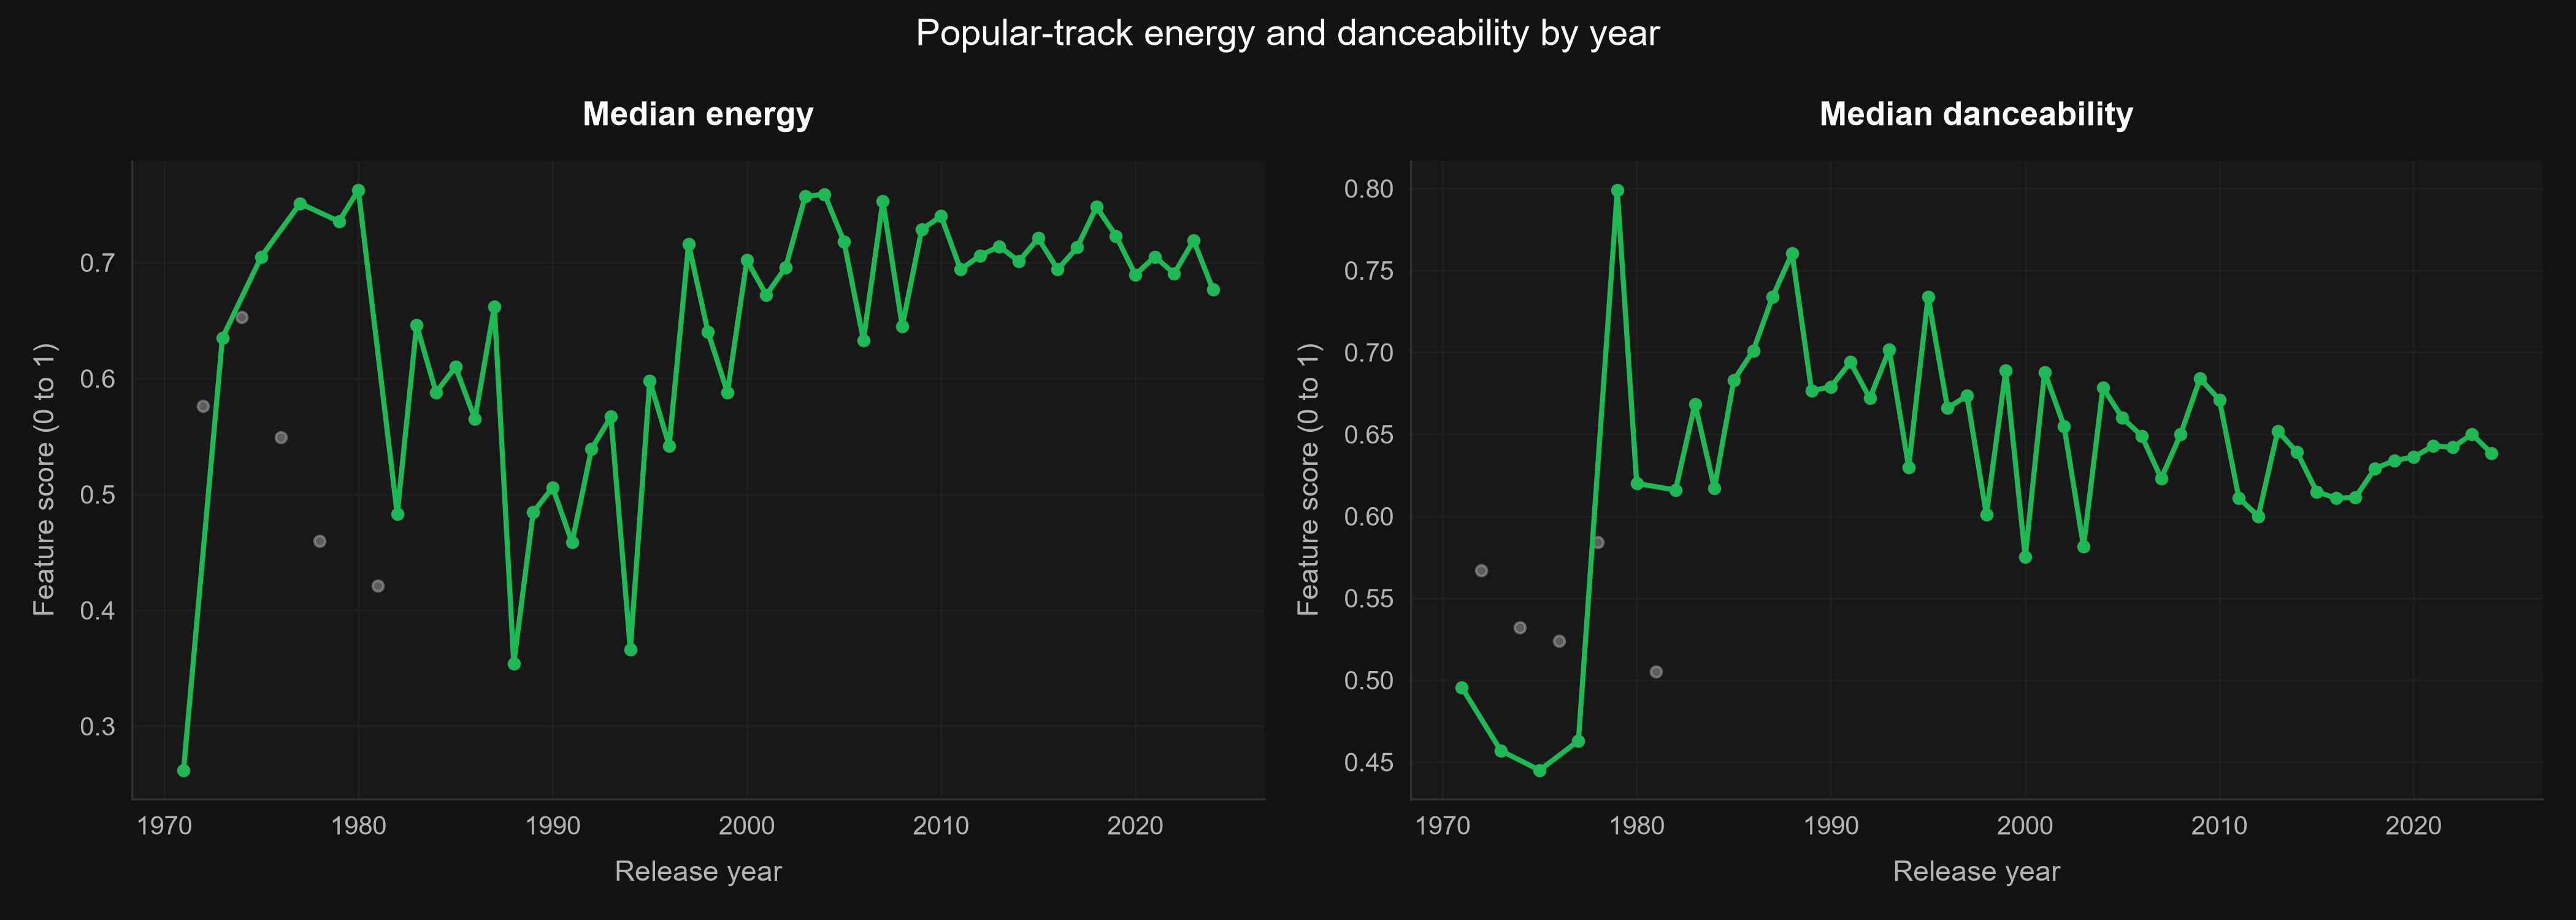

In [17]:
popularity_cutoff = df_clean['popularity'].quantile(.75)
popular_tracks = df_clean.loc[df_clean['popularity'] >= popularity_cutoff].copy()
popular_tracks['decade'] = (popular_tracks['year'] // 10) * 10
print(f'Global popularity Q3 cutoff: {popularity_cutoff:.2f}; selected {len(popular_tracks):,} tracks ({len(popular_tracks)/len(df_clean):.1%}, ties included)')
popular_audio = popular_tracks.groupby('year').agg(energy=('energy','median'), energy_n=('energy','count'), danceability=('danceability','median'), danceability_n=('danceability','count'))
fig, axes = plt.subplots(1,2,figsize=(14,5),sharex=True)
for ax, value, count, label in [(axes[0],'energy','energy_n','Median energy'),(axes[1],'danceability','danceability_n','Median danceability')]:
    s=popular_audio[value].dropna(); ax.scatter(s.index,s.values,color=muted_grey,alpha=.45,s=18)
    idx=popular_audio.index[popular_audio[count]>=10]; ax.plot(idx,popular_audio.loc[idx,value],color=spotify_green,marker='o',lw=2,ms=4)
    ax.set(title=label,xlabel='Release year',ylabel='Feature score (0 to 1)'); ax.grid(alpha=.3)
plt.suptitle('Popular-track energy and danceability by year'); plt.tight_layout(); plt.savefig('outputs/graphs/temporal/popular_energy_danceability_by_year.png',dpi=300); plt.show(block=False); plt.close()
print(popular_audio.round(3))

### Actuals B — key and tempo prevalence

**Question:** Did key or tempo-band mix change among popular tracks? Heatmap colors show within-year percentages, not counts, so years with more tracks do not automatically look more prevalent. Key codes are categories, not ordered quantities. Tempo bands use fixed full-dataset quartile boundaries.

Fixed tempo cut points (BPM): [95.95, 117.99, 135.08]
      popular_track_n
year                 
2013              758
2014              698
2015              661
2016              826
2017              824
2018              759
2019              837
2020             1182
2021             1297
2022             1304
2023             1444
2024              796


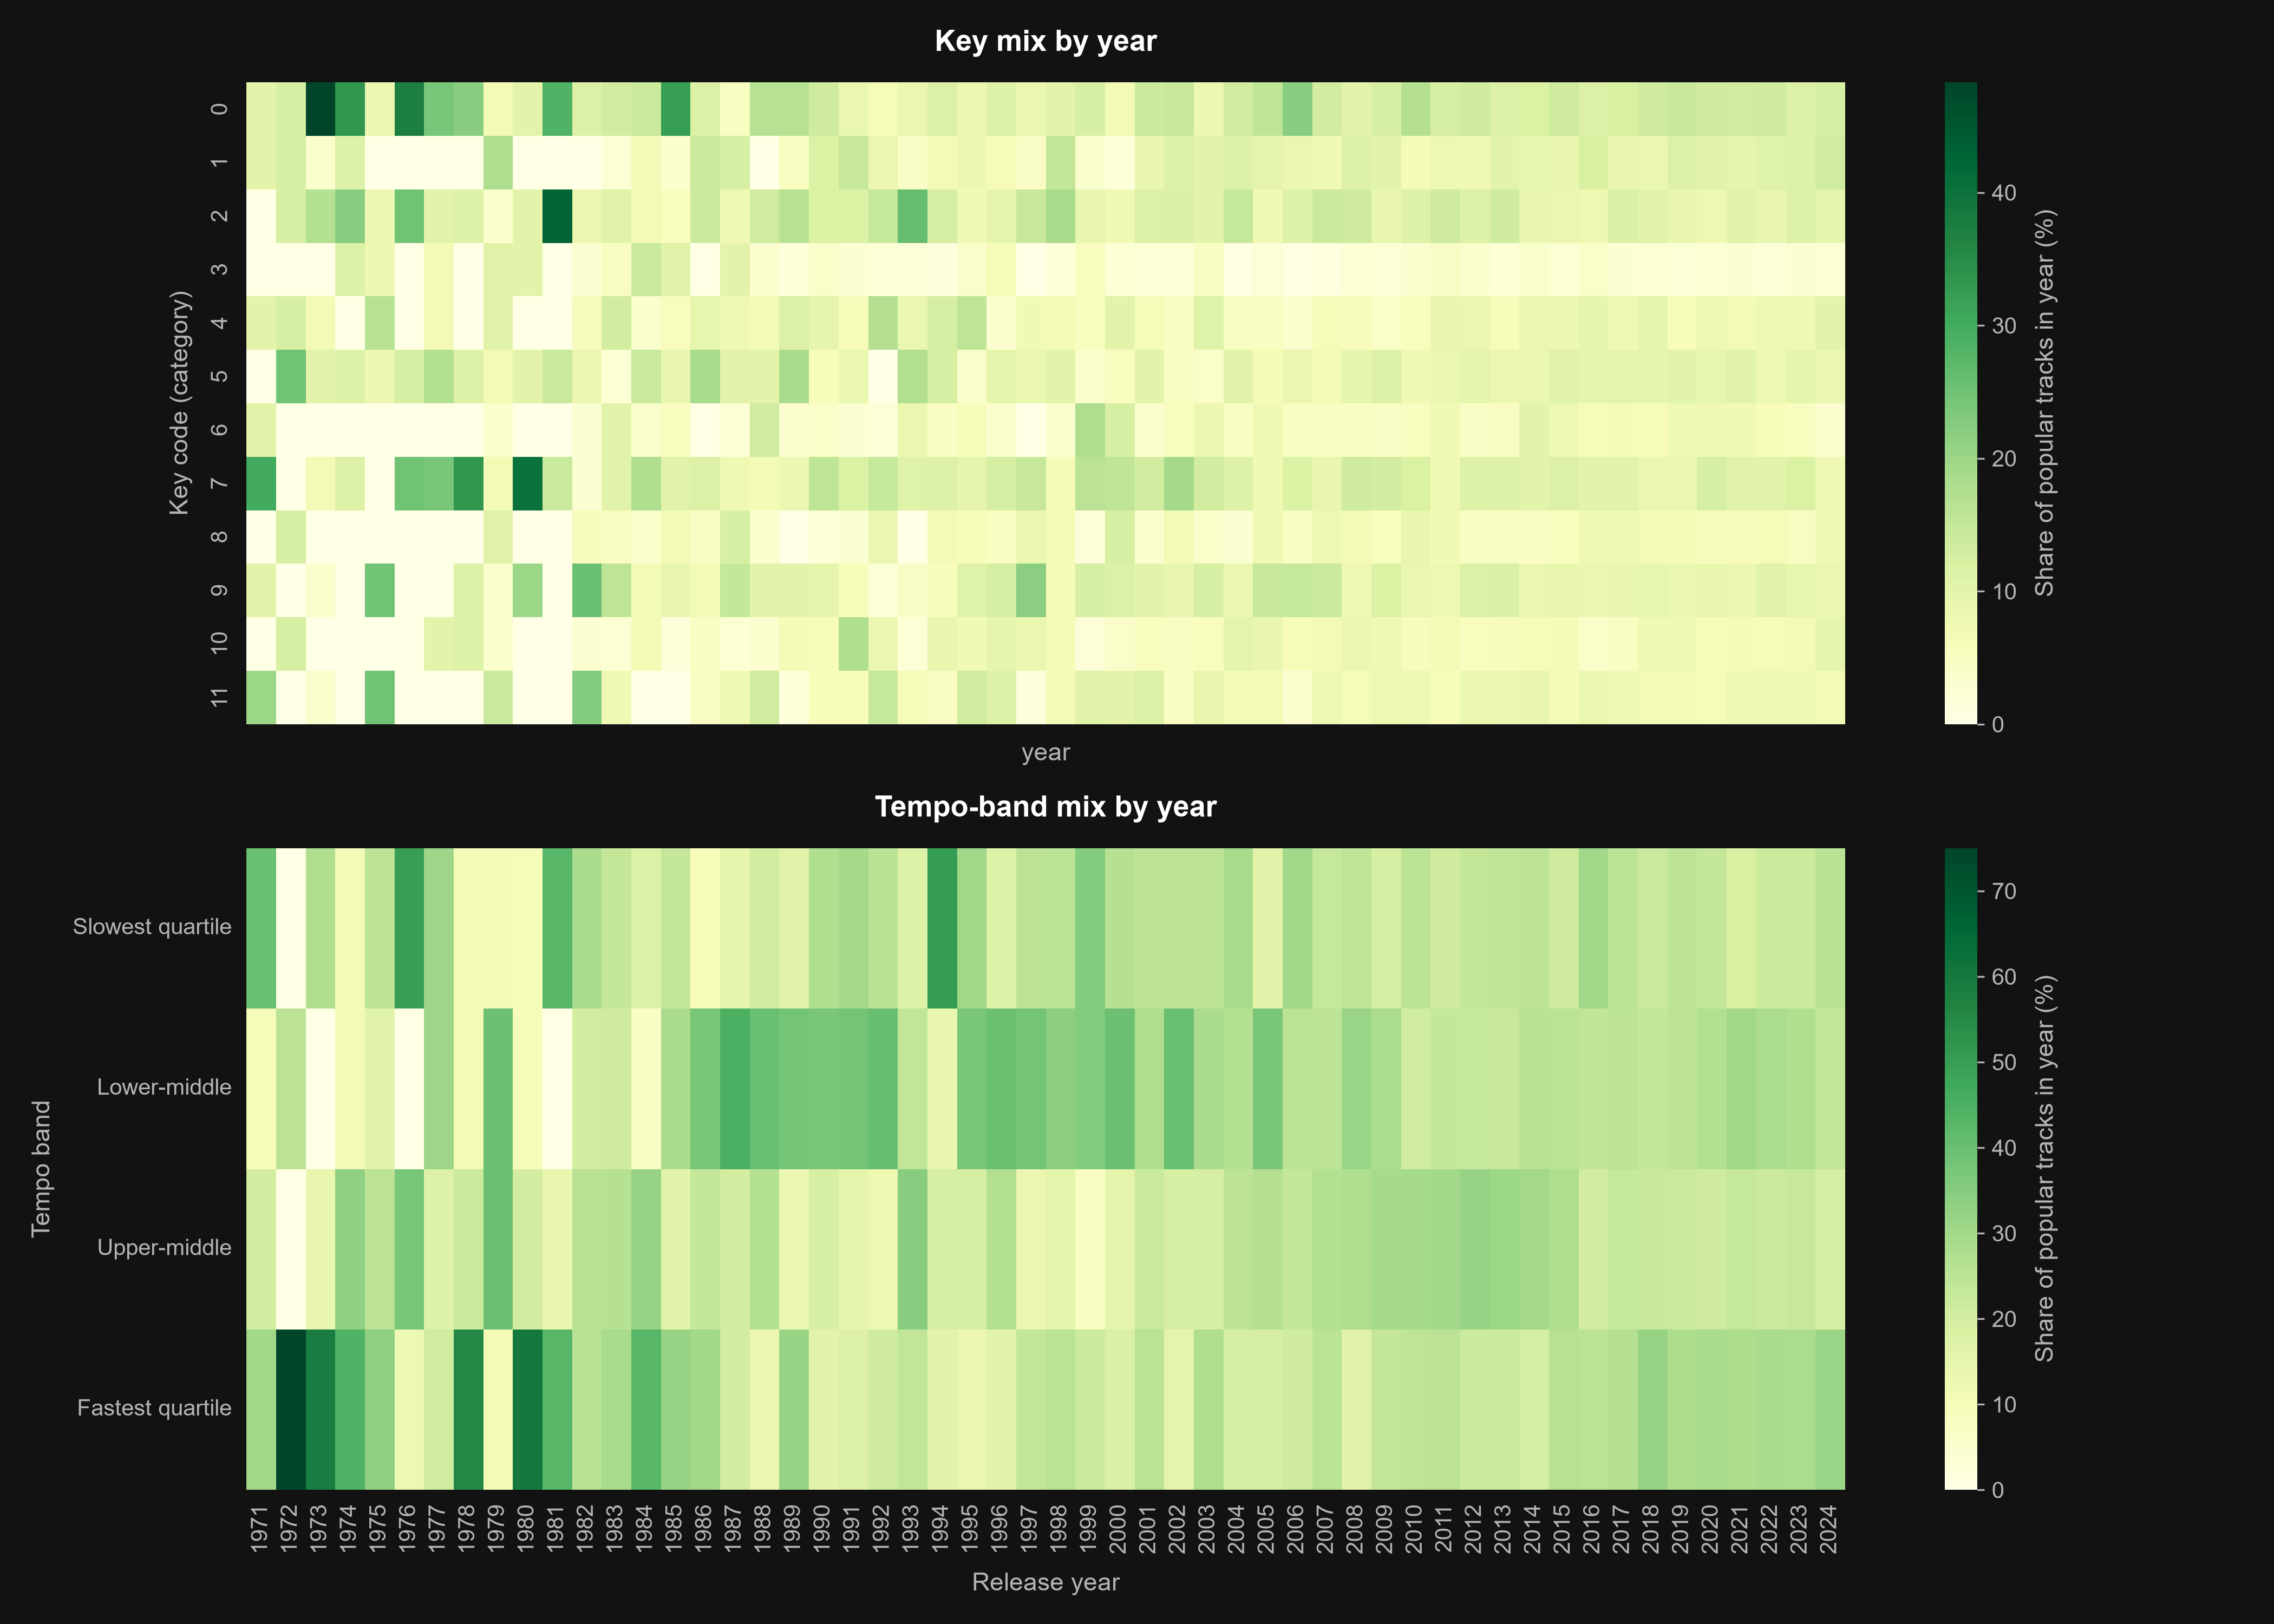

In [18]:
tempo_edges=[-np.inf,*df_clean['tempo'].quantile([.25,.5,.75]).tolist(),np.inf]; tempo_labels=['Slowest quartile','Lower-middle','Upper-middle','Fastest quartile']
popular_tracks['tempo_band']=pd.cut(popular_tracks['tempo'],bins=tempo_edges,labels=tempo_labels,include_lowest=True)
key_share=pd.crosstab(popular_tracks['year'],popular_tracks['key'],normalize='index').reindex(columns=range(12),fill_value=0)*100
tempo_share=pd.crosstab(popular_tracks['year'],popular_tracks['tempo_band'],normalize='index').reindex(columns=tempo_labels,fill_value=0)*100
fig,axes=plt.subplots(2,1,figsize=(14,10),sharex=True)
sns.heatmap(key_share.T,ax=axes[0],cmap='YlGn',cbar_kws={'label':'Share of popular tracks in year (%)'}); axes[0].set(title='Key mix by year',ylabel='Key code (category)')
sns.heatmap(tempo_share.T,ax=axes[1],cmap='YlGn',cbar_kws={'label':'Share of popular tracks in year (%)'}); axes[1].set(title='Tempo-band mix by year',ylabel='Tempo band',xlabel='Release year')
plt.tight_layout(); plt.savefig('outputs/graphs/temporal/popular_key_tempo_prevalence_by_year.png',dpi=300); plt.show(block=False); plt.close()
print('Fixed tempo cut points (BPM):',[round(x,2) for x in tempo_edges[1:-1]])
print(popular_tracks.groupby('year').size().rename('popular_track_n').to_frame().tail(12))

### Actuals C — popular-track duration by decade

The point is the median duration; the thick vertical mark spans Q1–Q3 (middle half). Milliseconds are converted to minutes. Decades stabilize sparse yearly groups; a wider band means greater variation in the middle half.

           n  median    q1    q3  mean
decade                                
1970     142    4.08  3.36  4.95  4.29
1980     347    4.51  4.11  4.78  4.53
1990     594    4.85  4.00  5.39  4.68
2000    1906    4.44  3.59  5.20  4.46
2010    7039    3.90  3.40  4.59  4.04
2020    6023    3.47  3.04  3.99  3.53


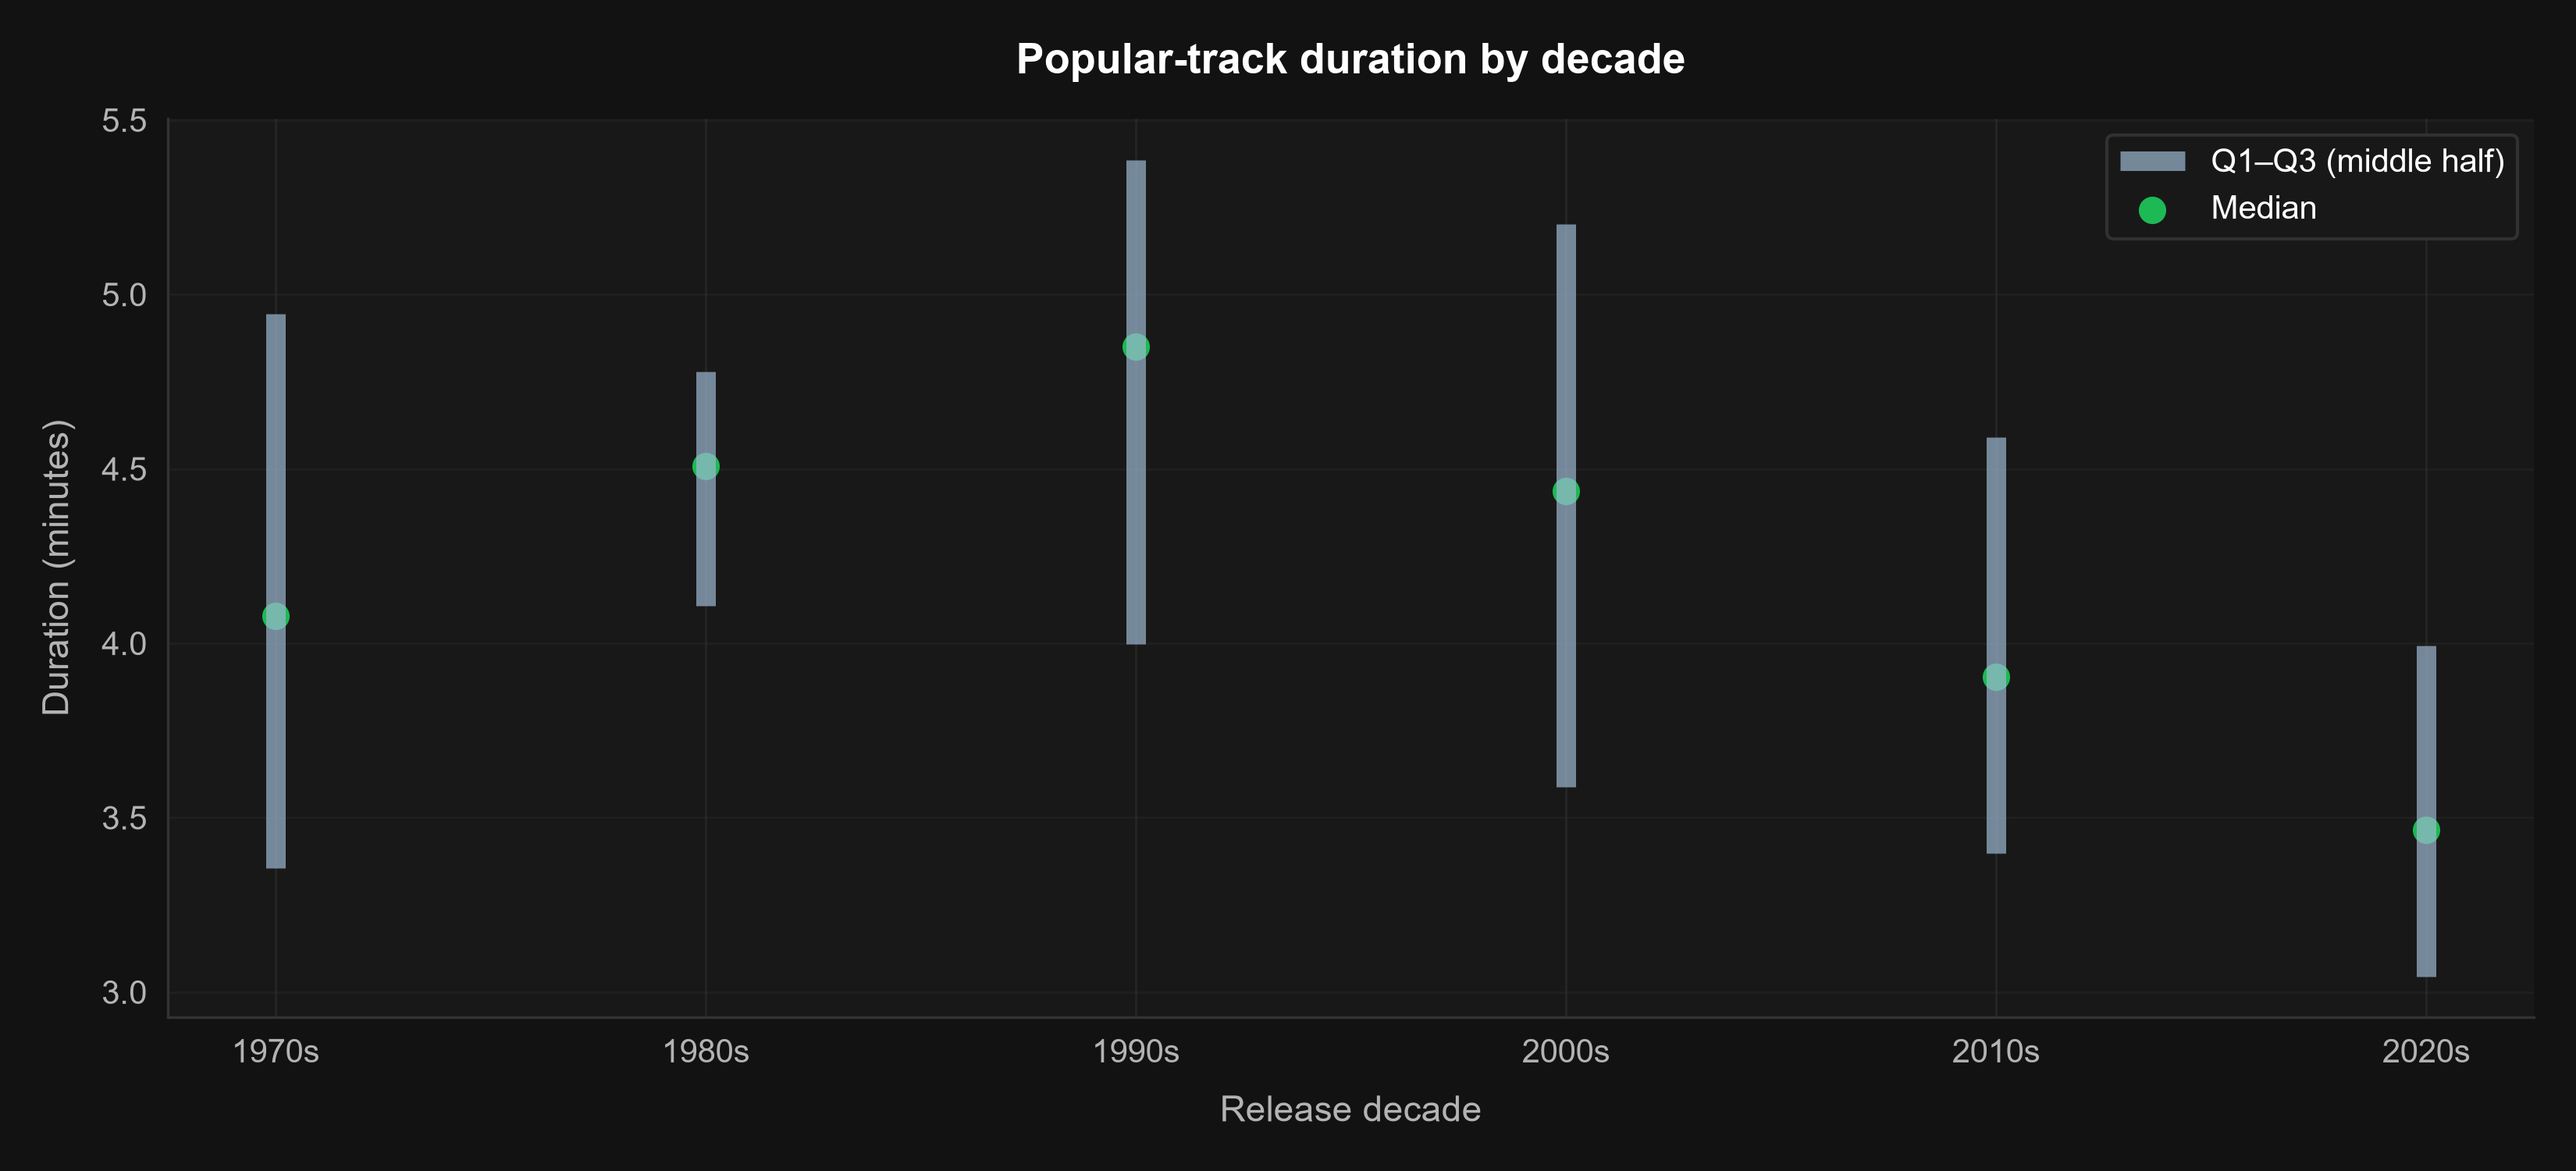

In [19]:
popular_tracks['duration_minutes']=popular_tracks['duration_ms']/60000
duration_decade=popular_tracks.groupby('decade')['duration_minutes'].agg(n='count',median='median',q1=lambda x:x.quantile(.25),q3=lambda x:x.quantile(.75),mean='mean').dropna()
fig,ax=plt.subplots(figsize=(11,5)); ax.vlines(duration_decade.index,duration_decade.q1,duration_decade.q3,color=muted_blue,lw=6,alpha=.7,label='Q1–Q3 (middle half)'); ax.scatter(duration_decade.index,duration_decade['median'],color=spotify_green,s=55,label='Median')
ax.set(xticks=duration_decade.index,xticklabels=[f'{int(y)}s' for y in duration_decade.index],title='Popular-track duration by decade',xlabel='Release decade',ylabel='Duration (minutes)'); ax.legend(); ax.grid(axis='y',alpha=.3)
plt.tight_layout(); plt.savefig('outputs/graphs/temporal/popular_duration_by_decade.png',dpi=300); plt.show(block=False); plt.close(); print(duration_decade.round(2))

### Actuals D — acousticness and instrumentalness

Two panels show yearly mean audio-feature scores among the same popular subset, with valid sample counts in the table. Small groups stay visible as faint points; the emphasized line is shown for groups with at least 10 valid tracks. These scores are proxies, not definitive production-style or genre labels.

      acousticness  acousticness_n  instrumentalness  instrumentalness_n
year                                                                    
1971         0.826              10             0.163                  10
1972         0.354               8             0.000                   8
1973         0.439              29             0.033                  29
1974         0.514               9             0.105                   9
1975         0.135              12             0.014                  12
1976         0.458               8             0.000                   8
1977         0.391              29             0.000                  29
1978         0.219               9             0.009                   9
1979         0.253              28             0.041                  28
1980         0.204              10             0.000                  10
1981         0.602               7             0.000                   7
1982         0.456              35             0.05

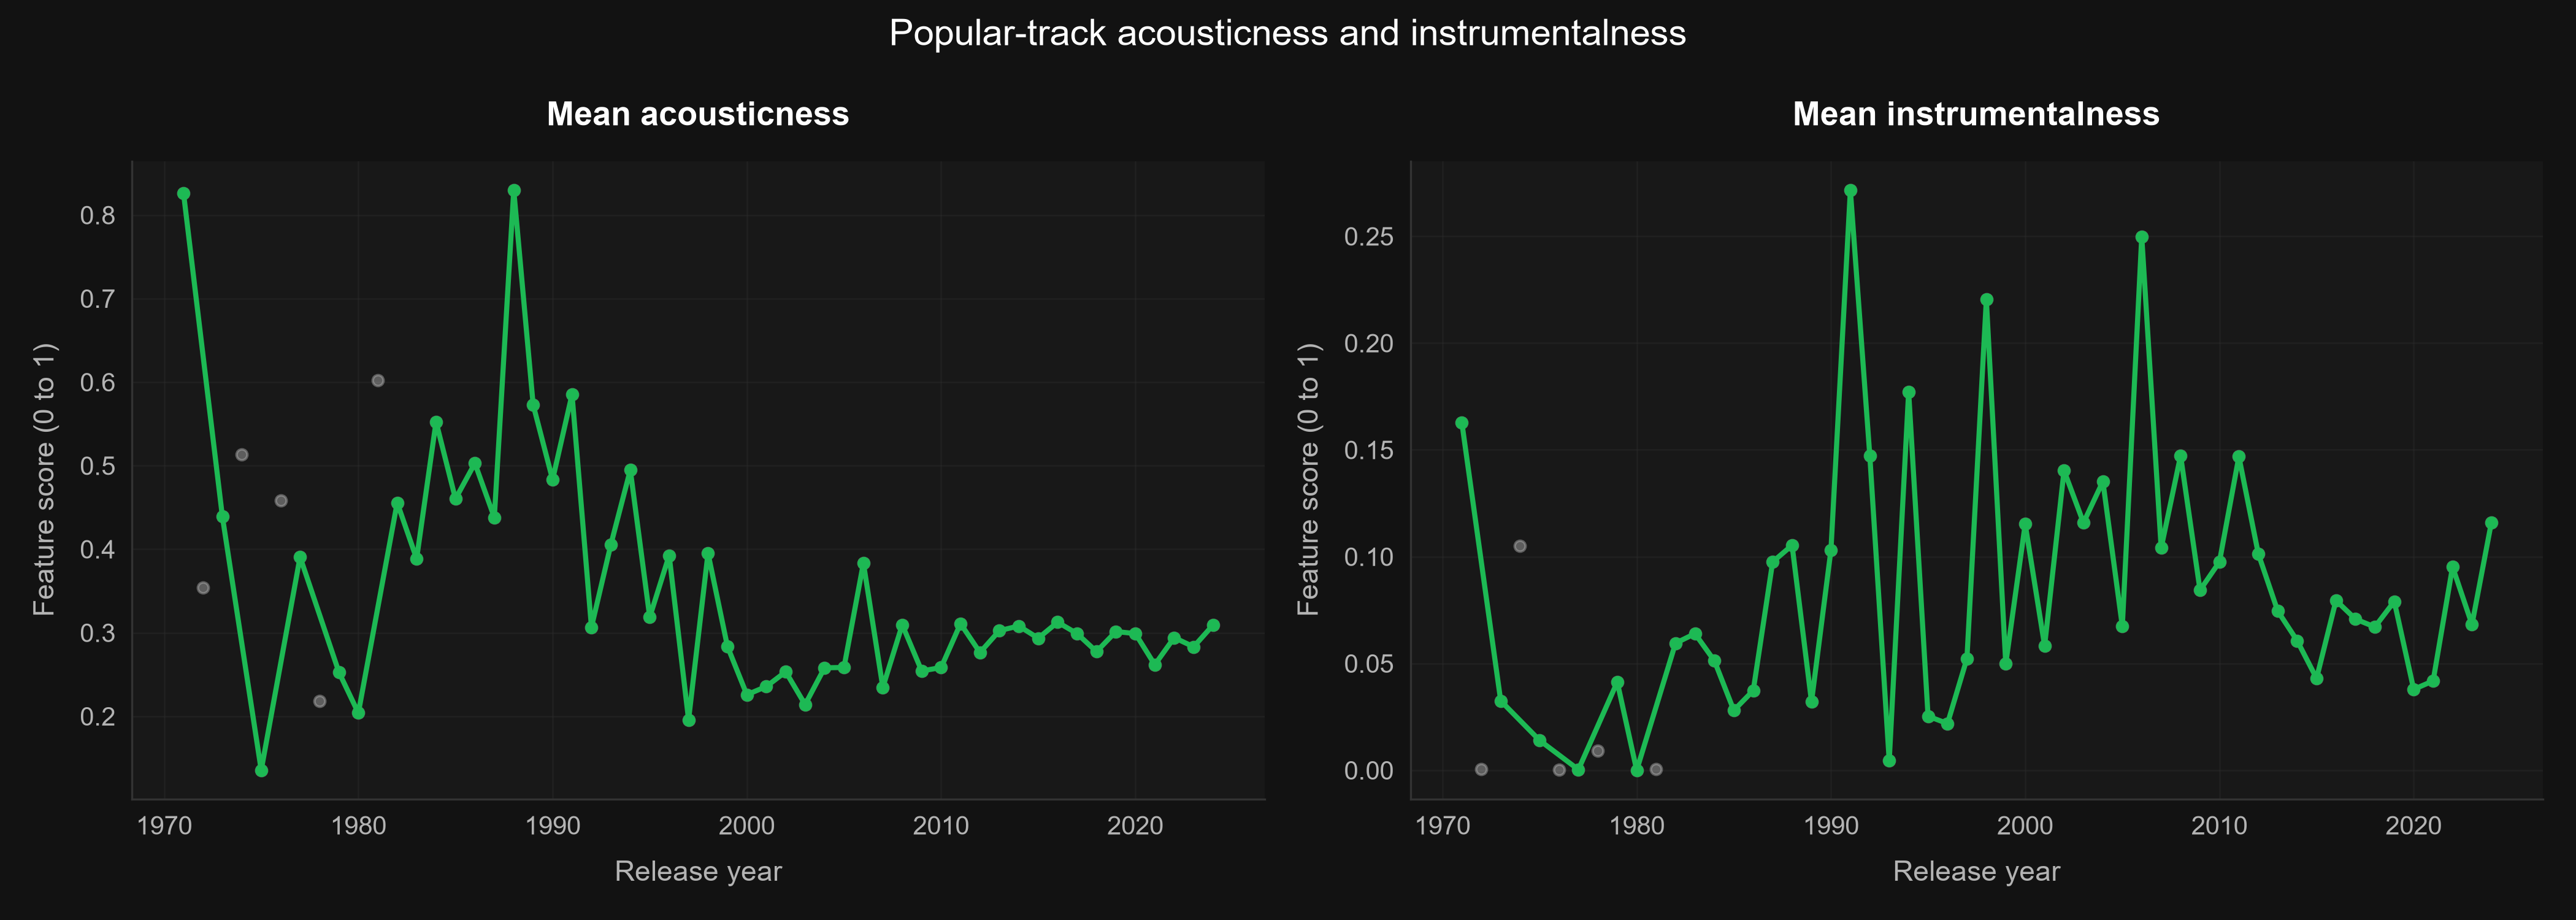

In [20]:
popular_style=popular_tracks.groupby('year').agg(acousticness=('acousticness','mean'),acousticness_n=('acousticness','count'),instrumentalness=('instrumentalness','mean'),instrumentalness_n=('instrumentalness','count'))
fig,axes=plt.subplots(1,2,figsize=(14,5),sharex=True)
for ax,value,count,label in [(axes[0],'acousticness','acousticness_n','Mean acousticness'),(axes[1],'instrumentalness','instrumentalness_n','Mean instrumentalness')]:
    s=popular_style[value].dropna(); ax.scatter(s.index,s.values,color=muted_grey,alpha=.45,s=18); idx=popular_style.index[popular_style[count]>=10]; ax.plot(idx,popular_style.loc[idx,value],color=spotify_green,marker='o',lw=2,ms=4); ax.set(title=label,xlabel='Release year',ylabel='Feature score (0 to 1)'); ax.grid(alpha=.3)
plt.suptitle('Popular-track acousticness and instrumentalness'); plt.tight_layout(); plt.savefig('outputs/graphs/temporal/popular_acousticness_instrumentalness_by_year.png',dpi=300); plt.show(block=False); plt.close(); print(popular_style.round(3))

### Actuals E — loudness and speechiness across all tracks

Loudness uses a yearly median with a Q1–Q3 band; speechiness uses a yearly mean in a separate panel. The table shows valid n. Loudness is measured in dB; speechiness is an estimated audio score, not a direct lyric or rap classifier.

      loudness_n  loudness  loud_q1  loud_q3  speechiness_n  speechiness
year                                                                    
1971          12   -14.580  -15.896  -13.390             12        0.055
1972          21    -8.958   -9.903   -8.336             21        0.043
1973          62    -8.817  -12.159   -6.925             62        0.165
1974          10   -10.436  -11.096   -8.190             10        0.037
1975          19    -9.990  -11.018   -9.467             19        0.047
1976           9   -10.156  -11.986   -9.047              9        0.043
1977          39    -7.526  -10.285   -6.314             39        0.088
1978          14   -14.115  -15.340   -9.646             14        0.067
1979          46    -6.481  -10.785   -4.826             46        0.070
1980          20    -7.387  -10.385   -6.581             20        0.075
1981          37    -9.041  -12.544   -7.480             37        0.115
1982         164    -9.838  -11.806   -8.228       

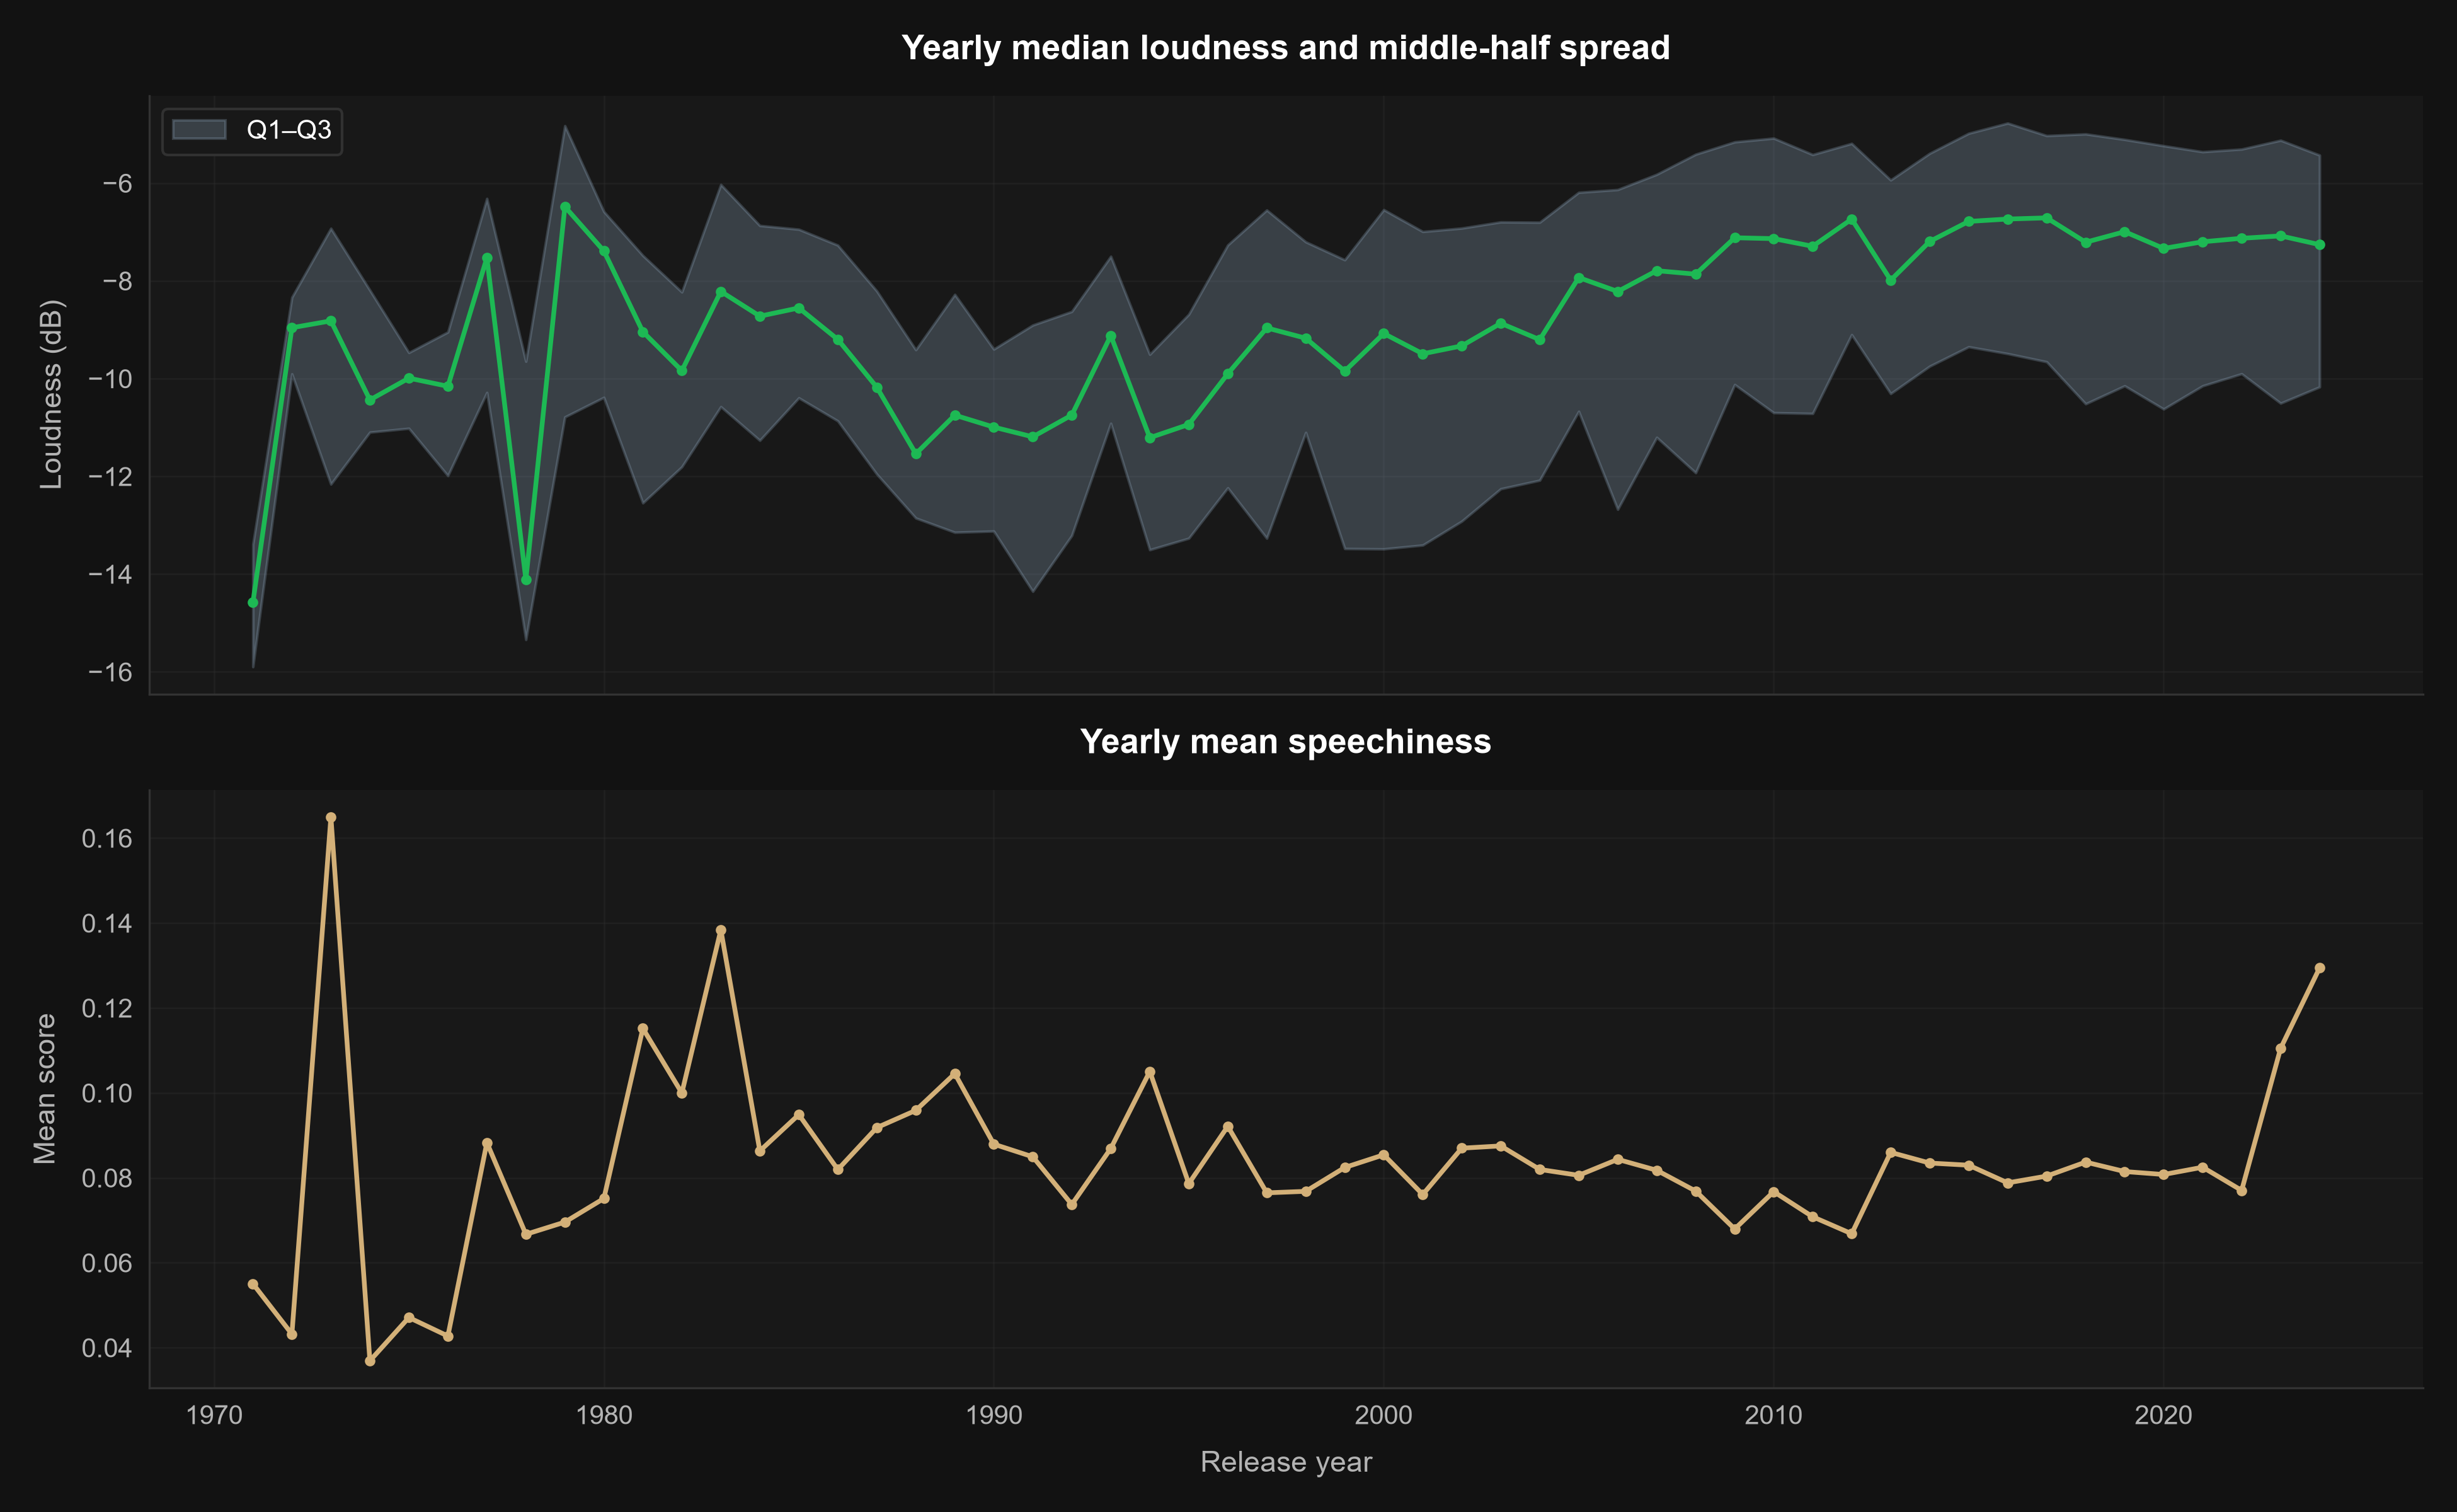

In [21]:
loud_speech=df_clean.groupby('year').agg(loudness_n=('loudness','count'),loudness=('loudness','median'),loud_q1=('loudness',lambda x:x.quantile(.25)),loud_q3=('loudness',lambda x:x.quantile(.75)),speechiness_n=('speechiness','count'),speechiness=('speechiness','mean'))
fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True); axes[0].fill_between(loud_speech.index,loud_speech.loud_q1,loud_speech.loud_q3,color=muted_blue,alpha=.25,label='Q1–Q3'); axes[0].plot(loud_speech.index,loud_speech.loudness,color=spotify_green,marker='o',ms=3); axes[0].set(title='Yearly median loudness and middle-half spread',ylabel='Loudness (dB)'); axes[0].legend()
axes[1].plot(loud_speech.index,loud_speech.speechiness,color=muted_sand,marker='o',ms=3); axes[1].set(title='Yearly mean speechiness',xlabel='Release year',ylabel='Mean score')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/graphs/temporal/yearly_loudness_speechiness.png',dpi=300); plt.show(block=False); plt.close(); print(loud_speech.round(3))

### Actuals F — language composition by year

The heatmap uses within-year percentages so years with different totals are comparable. Unknown and missing labels remain visible. The supplied data has no Spanish category, so it cannot support a Spanish-specific trend.

year            2015  2016  2017  2018  2019  2020  2021  2022  2023  2024
language_label                                                            
English         25.6  23.0  23.7  20.0  31.4  42.6  44.5  52.0  40.3  61.5
Hindi            8.4  12.3  16.6   8.9  14.2  12.0  10.7  13.1  17.7   8.6
Korean          15.9  21.8  18.0  21.5  19.2  19.6  18.2  10.9  10.8   4.1
Malayalam        0.5   2.1   0.4   0.3   0.2   1.0   1.1   0.7   0.5   0.5
Tamil           21.6  17.1  15.0  18.2  12.1   9.4   8.2   8.9   9.6  18.1
Telugu           0.3   0.8   0.0   0.6   0.2   0.8   1.6   1.2   0.7   0.4
Unknown         27.6  22.9  26.3  30.4  22.6  14.6  15.7  13.2  20.4   6.7


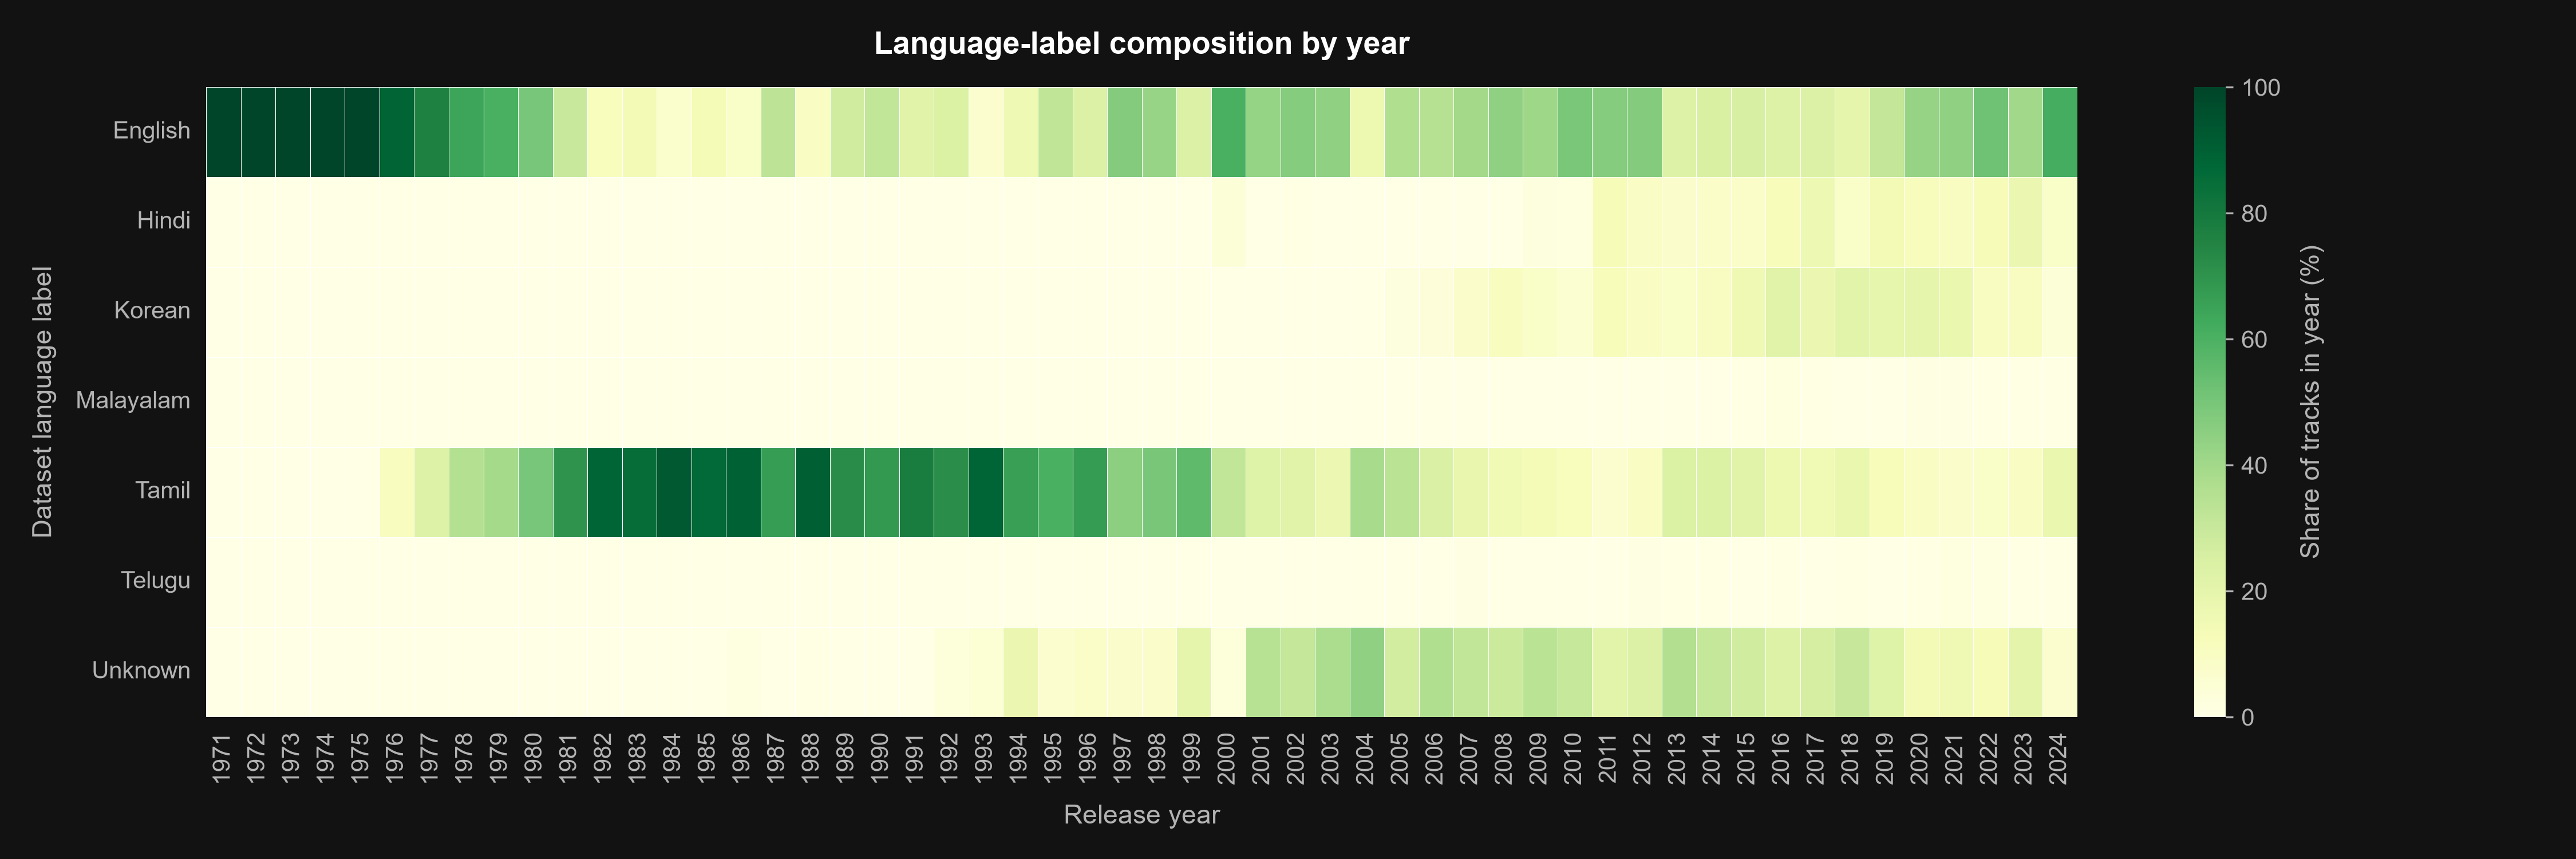

In [22]:
language_data=df_clean.assign(language_label=df_clean['language'].fillna('Missing').replace('', 'Unknown'))
language_share=pd.crosstab(language_data.language_label,language_data.year,normalize='columns')*100
fig,ax=plt.subplots(figsize=(15,max(5,.45*len(language_share)))); sns.heatmap(language_share,cmap='YlGn',linewidths=.15,cbar_kws={'label':'Share of tracks in year (%)'},ax=ax); ax.set(title='Language-label composition by year',xlabel='Release year',ylabel='Dataset language label')
plt.tight_layout(); plt.savefig('outputs/graphs/temporal/language_share_by_year.png',dpi=300); plt.show(block=False); plt.close(); print(language_share.iloc[:,-10:].round(1))

### Actuals G — liveness among popular tracks

The line shows decade-level median liveness for the same popular-track group; labels give valid n. Higher scores suggest stronger live-performance characteristics in the audio estimate, not a verified live recording.

           n  median   mean
decade                     
1970     142   0.123  0.208
1980     347   0.117  0.182
1990     594   0.118  0.167
2000    1906   0.119  0.197
2010    7039   0.126  0.196
2020    6020   0.123  0.180


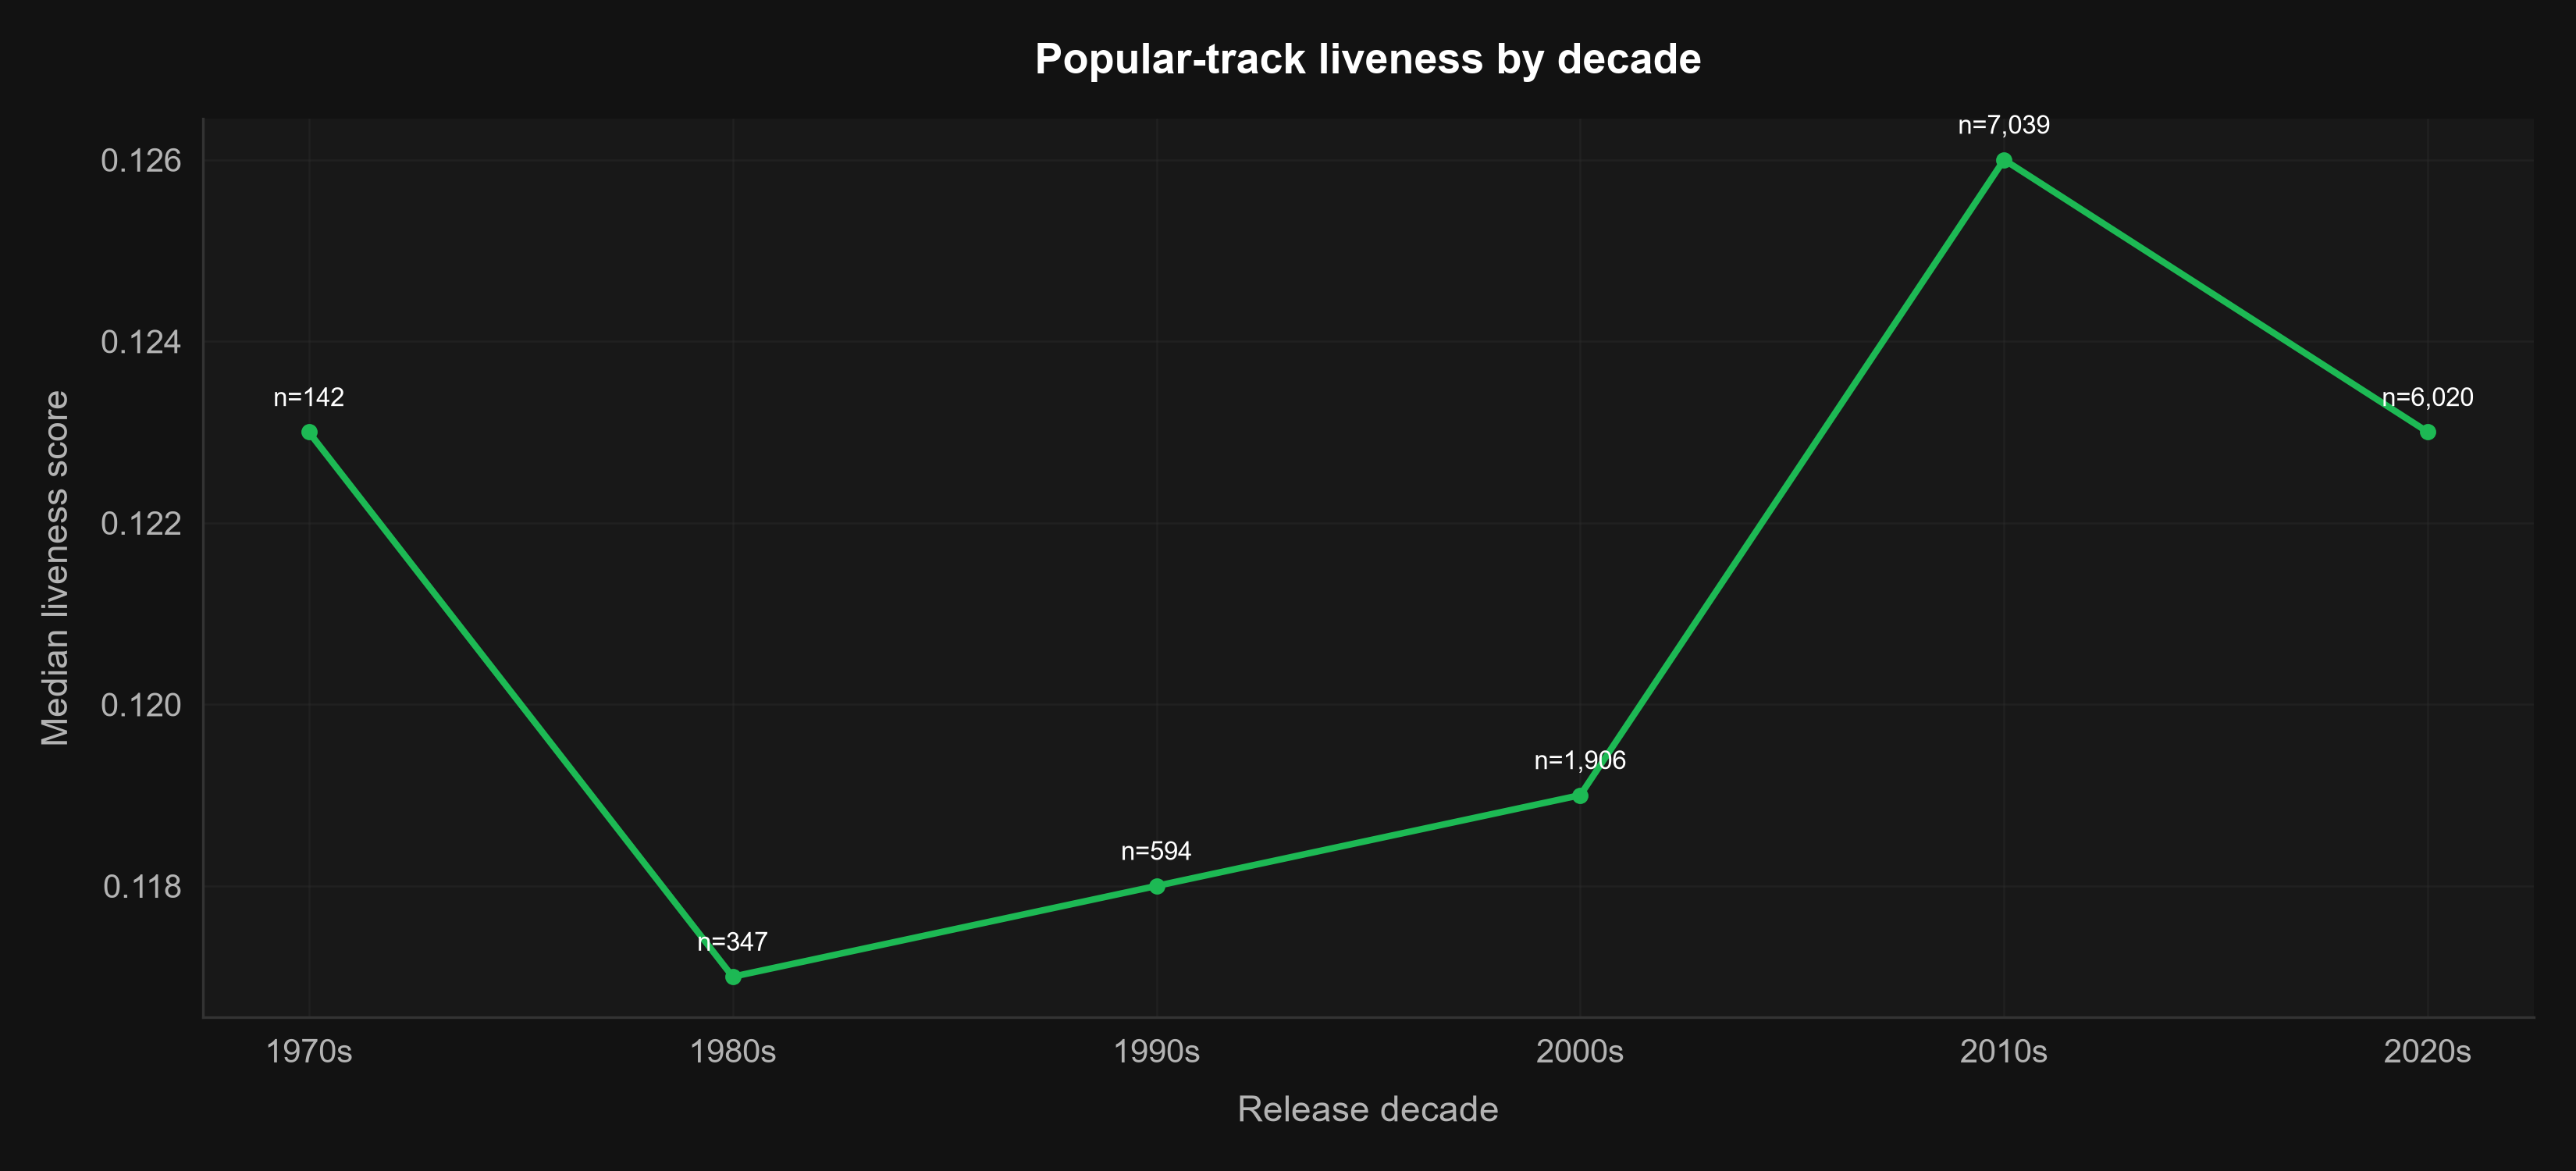

In [23]:
live_decade=popular_tracks.groupby('decade').liveness.agg(n='count',median='median',mean='mean').dropna()
fig,ax=plt.subplots(figsize=(11,5)); ax.plot(live_decade.index,live_decade['median'],color=spotify_green,marker='o',lw=2)
for decade,row in live_decade.iterrows(): ax.annotate(f"n={int(row['n']):,}",(decade,row['median']),xytext=(0,8),textcoords='offset points',ha='center',fontsize=8)
ax.set(xticks=live_decade.index,xticklabels=[f'{int(y)}s' for y in live_decade.index],title='Popular-track liveness by decade',xlabel='Release decade',ylabel='Median liveness score'); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('outputs/graphs/temporal/popular_liveness_by_decade.png',dpi=300); plt.show(block=False); plt.close(); print(live_decade.round(3))

### Actuals H — energy–danceability correlation by decade

Each point is the decade-specific Pearson correlation among all tracks; labels give valid pair n. Zero means no straight-line association and positive values indicate that higher energy tends to occur with higher danceability. This does not show causation, and small groups are less stable.

              n  pearson_r
decade                    
1970      232.0      0.199
1980     1863.0      0.116
1990     3738.0      0.474
2000     7144.0      0.552
2010    25442.0      0.497
2020    23785.0      0.449


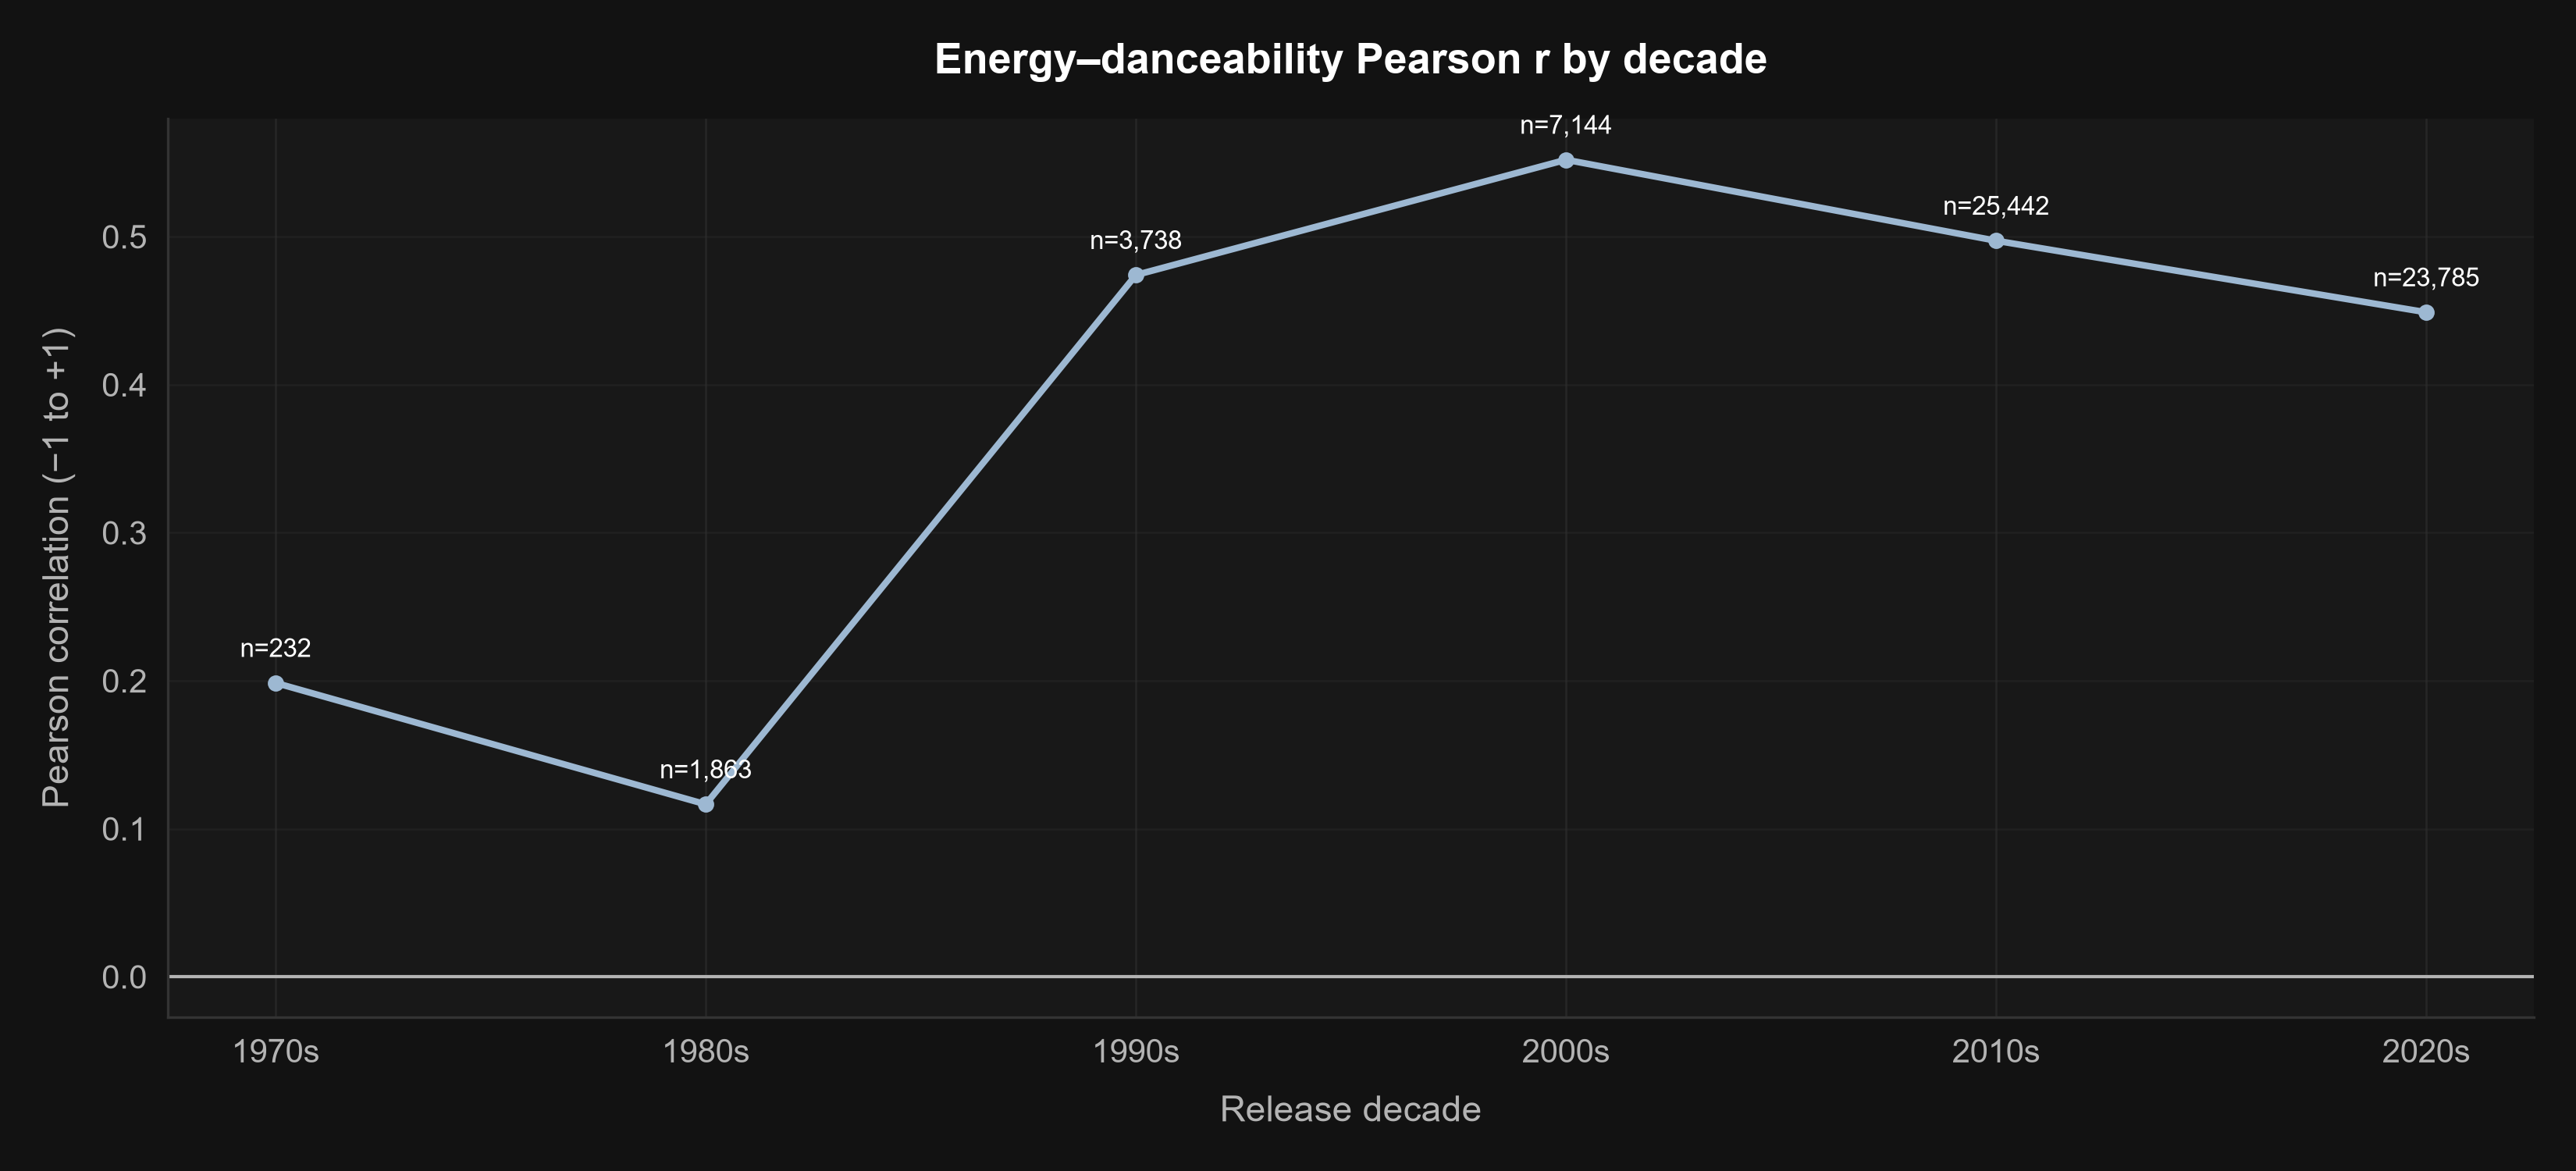

In [24]:
df_clean['decade']=(df_clean.year//10)*10
decade_corr=df_clean.groupby('decade').apply(lambda g:pd.Series({'n':g[['energy','danceability']].dropna().shape[0],'pearson_r':g.energy.corr(g.danceability)}),include_groups=False).dropna()
fig,ax=plt.subplots(figsize=(11,5)); ax.axhline(0,color=muted_grey,lw=1); ax.plot(decade_corr.index,decade_corr.pearson_r,color=muted_blue,marker='o',lw=2)
for decade,row in decade_corr.iterrows(): ax.annotate(f"n={int(row['n']):,}",(decade,row.pearson_r),xytext=(0,8),textcoords='offset points',ha='center',fontsize=8)
ax.set(xticks=decade_corr.index,xticklabels=[f'{int(y)}s' for y in decade_corr.index],title='Energy–danceability Pearson r by decade',xlabel='Release decade',ylabel='Pearson correlation (−1 to +1)'); ax.grid(axis='y',alpha=.3)
plt.tight_layout(); plt.savefig('outputs/graphs/temporal/energy_danceability_correlation_by_decade.png',dpi=300); plt.show(block=False); plt.close(); print(decade_corr.round(3))

### Time Series Analysis — Growth (year-over-year change)

Actuals show the value in each year; growth shows how it changed from the previous calendar year. Bars show percent change for track counts and point change for popularity/audio means. We reindex all calendar years first, so a missing year stays blank instead of comparing nonadjacent years. Count percentages can be huge when the previous count is tiny; read them beside the actual counts.


      track_count  ...  average_valence_point_change
year               ...                              
2010         1588  ...                        -0.037
2011         1621  ...                        -0.001
2012         1965  ...                        -0.006
2013         3362  ...                         0.077
2014         2787  ...                        -0.052
2015         2626  ...                         0.011
2016         2821  ...                        -0.037
2017         2896  ...                         0.009
2018         2971  ...                        -0.018
2019         2807  ...                        -0.004
2020         3035  ...                         0.001
2021         3698  ...                        -0.003
2022         5181  ...                         0.020
2023         6427  ...                         0.023
2024         5471  ...                        -0.016

[15 rows x 10 columns]


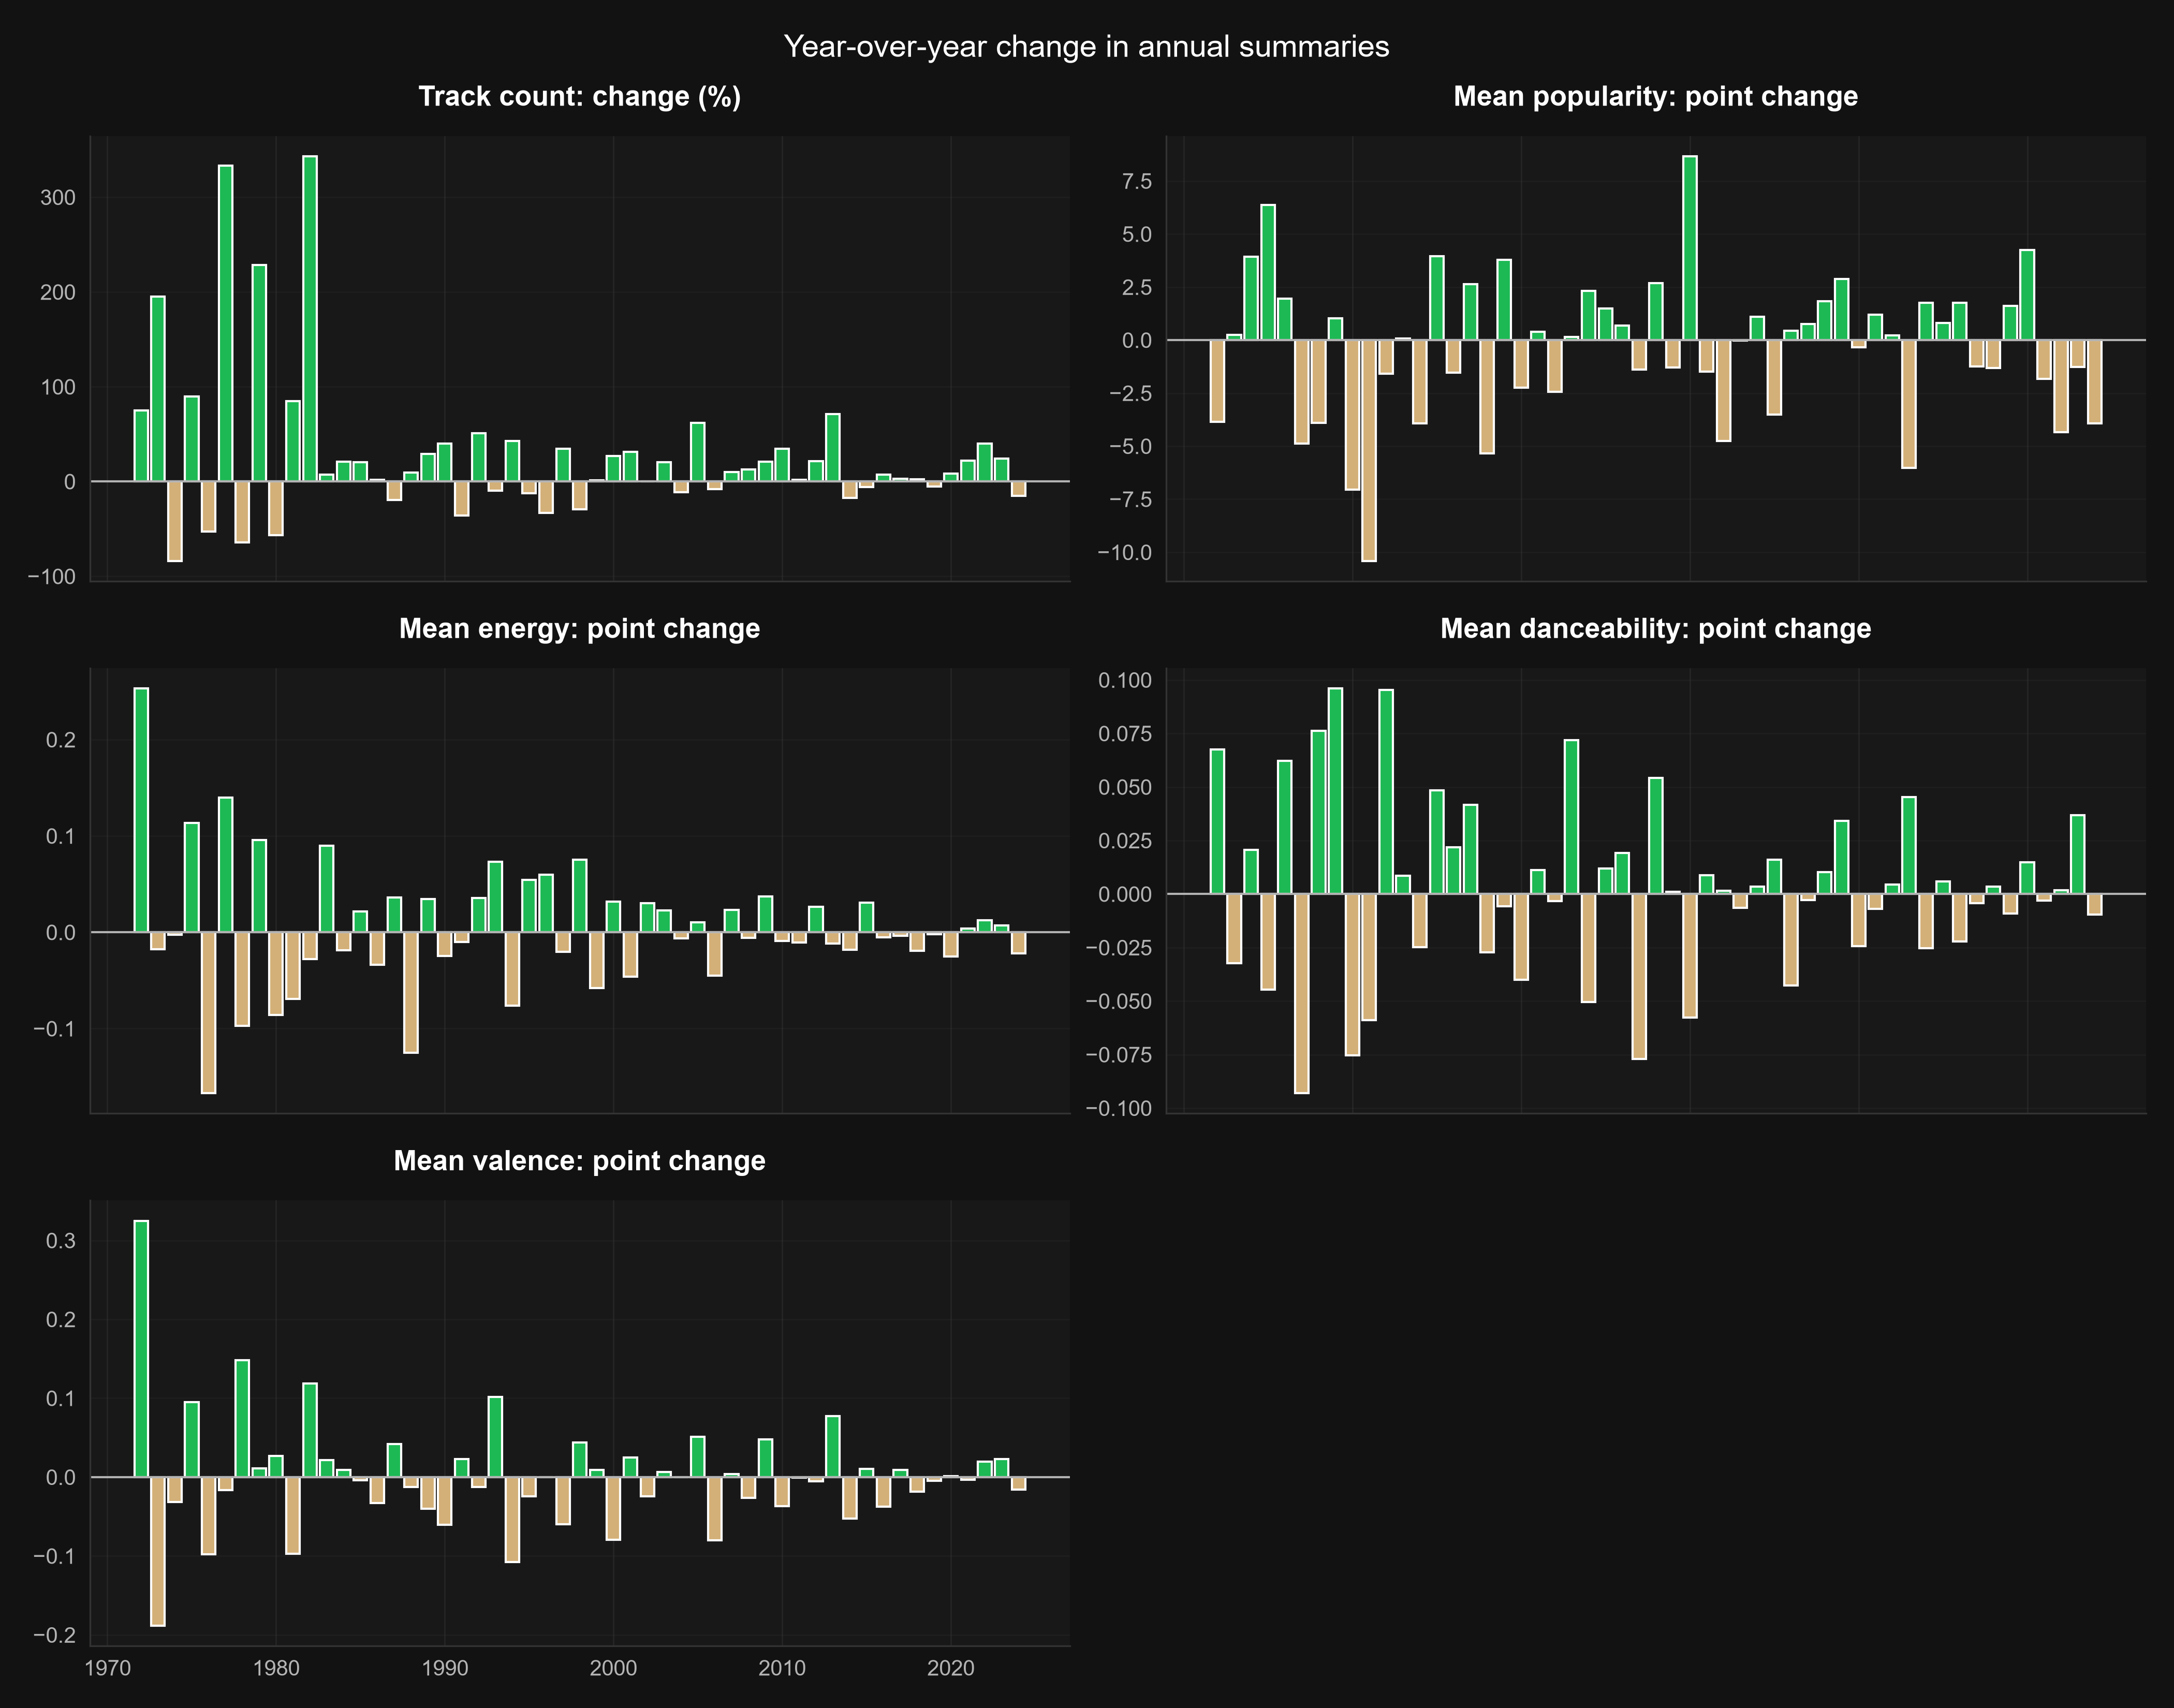

In [25]:
growth_actuals=yearly_summary[['track_count','average_popularity','average_energy','average_danceability','average_valence']].reindex(range(int(yearly_summary.index.min()),int(yearly_summary.index.max())+1))
growth=pd.DataFrame(index=growth_actuals.index); growth['track_count_pct']=growth_actuals.track_count.pct_change(fill_method=None)*100
for col in ['average_popularity','average_energy','average_danceability','average_valence']: growth[col+'_point_change']=growth_actuals[col].diff()
specs=[('track_count_pct','Track count: change (%)'),('average_popularity_point_change','Mean popularity: point change'),('average_energy_point_change','Mean energy: point change'),('average_danceability_point_change','Mean danceability: point change'),('average_valence_point_change','Mean valence: point change')]
fig,axes=plt.subplots(3,2,figsize=(14,11),sharex=True)
for ax,(col,title) in zip(axes.flat,specs):
    s=growth[col].dropna(); ax.bar(s.index,s.values,color=[spotify_green if x>=0 else muted_sand for x in s],width=.8); ax.axhline(0,color=muted_grey,lw=1); ax.set(title=title); ax.grid(axis='y',alpha=.25)
axes.flat[-1].axis('off'); plt.suptitle('Year-over-year change in annual summaries'); plt.tight_layout(); plt.savefig('outputs/graphs/temporal/year_over_year_growth.png',dpi=300); plt.show(block=False); plt.close()
print(pd.concat([growth_actuals,growth],axis=1).tail(15).round(3))

### Learning note for presenting these results

The global top-quartile cutoff is **26**; ties select **16,051 tracks (25.8%)**. This is a consistent working definition of “popular,” not an industry standard.

Among popular-track years with at least 10 valid observations, median energy spans **0.262 (1971) to 0.763 (1980)**; median danceability spans **0.445 (1975) to 0.799 (1979)**. These extrema are descriptive and old-year groups remain much smaller.

Fixed full-dataset tempo quartiles are **95.95, 117.99, and 135.08 BPM**. The key and tempo heatmaps show shares within each year, not popularity or absolute track volume.

Popular-track median duration by decade is **4.08 min (1970s), 4.51 (1980s), 4.85 (1990s), 4.44 (2000s), 3.90 (2010s), and 3.47 (2020s)**. These groups have different sizes; the recent decline is descriptive and the chart does not explain why.

For popular-track acousticness, annual median among groups n≥10 ranges **0.062 (1975) to 0.901 (1971)**. Instrumentalness medians are mostly zero; annual mean can be strongly affected by a small number of high values.

For all tracks, among years n≥30, median loudness ranges **−11.54 dB (1988) to −6.48 dB (1979)**; mean speechiness ranges **0.067 (2012) to 0.165 (1973)**. Neither pattern proves a “loudness war” or a genre change.

Popular-track median liveness by decade is tightly grouped here, about **0.117–0.126**. That range does not verify whether a recording is live.

Energy–danceability Pearson r by decade is **0.199 (1970s), 0.116 (1980s), 0.474 (1990s), 0.552 (2000s), 0.497 (2010s), and 0.449 (2020s)**. Association is positive in each decade, strongest in the 2000s, and never evidence that one feature causes the other.

The growth bars show year-over-year changes in summaries. Rows are separate release-year groups and popularity is a current snapshot score, so they do not track how an individual song's score changed over its life.

When presenting, state what was measured and filtered, the pattern and `n`, its plain-language meaning, then a limitation. Univariate, Bivariate, Multivariate/outlier sections and the final PDF remain shared teammate/integration tasks.


## 11. Recommendations — evidence and limits

### Supported actions to consider

1. **Validate data on every refresh.** Check exact duplicates, sentinel values, missing language, and reasonable ranges before using summaries.
2. **Run creative tests instead of copying a formula.** The energy/popularity correlation is weak (r=0.147). Test alternative arrangements with a fair comparison and measurable audience outcomes.
3. **Research audience segments carefully.** Korean-tagged tracks have the highest language mean in this file (27.55; median 26; n=6,893), but group averages do not explain why. Compare multiple releases and include sample sizes.
4. **Use historical trends as context.** Pair release timing ideas with current audience data; year patterns are not forecasts.

Possible success measures for a future test include saves, completion rate, repeat listening, and campaign conversion. These measures are not present in this CSV, so do not claim measured business impact here.


In [26]:
print('Energy/popularity Pearson r:', df_clean['energy'].corr(df_clean['popularity']))
print('Danceability/popularity Pearson r:', df_clean['danceability'].corr(df_clean['popularity']))
print('Valence/popularity Pearson r:', df_clean['valence'].corr(df_clean['popularity']))
print('Acousticness/popularity Pearson r:', df_clean['acousticness'].corr(df_clean['popularity']))
print('Instrumentalness/popularity Pearson r:', df_clean['instrumentalness'].corr(df_clean['popularity']))
print('Energy/danceability Pearson r:', df_clean['energy'].corr(df_clean['danceability']))


Energy/popularity Pearson r: 0.14740280972028527
Danceability/popularity Pearson r: 0.042057824869718645
Valence/popularity Pearson r: 0.009150280465131388
Acousticness/popularity Pearson r: -0.1384326727423155
Instrumentalness/popularity Pearson r: -0.12714405972360177
Energy/danceability Pearson r: 0.46564902980639494


## 12. Limitations

- The dataset's language and year counts are uneven; the collection process is not fully documented.
- The popularity score is current and can reflect track age, promotion, artist reach, and platform exposure.
- The data have no listener-level demographics, listening histories, genre labels, or stream-event counts.
- Correlation and group averages are descriptive; no causal effect or future success is established.
- Member 1–3 sections and the subjective-answer PDF must still be integrated after review.


## 13. Conclusion

This dataset supports a careful description of track features and their observed relationships. Popularity is typically low (processed median 7), energy has only a weak positive correlation with popularity (r=0.147), and historical sample sizes vary widely. The responsible next step is to complete the teammate analyses, test recommendations with audience data, and avoid presenting a feature combination as a guaranteed hit formula.

### Source and project files

- Supplied data: `spotify_tracks.csv`
- Data dictionary: `spotify_data_description.csv`
- Reference audit: `outputs/reports/REFERENCE_AUDIT.md`
- Data profile: `outputs/reports/DATASET_PROFILE.md`
- Final project requirements and setup: `README.md`
